# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [3]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [4]:
#!rm SUSY.csv

In [5]:
#!gunzip SUSY.csv.gz

In [6]:
ls -lh

total 2.5G
-rw-r--r-- 1 kingbam kingbam 4.6M Oct 31 00:52 Lab.7.Copy.ipynb
-rw-r--r-- 1 kingbam kingbam 357K Oct  9 21:29 Lab.7.ipynb
-rw-r--r-- 1 kingbam kingbam 150K Oct  9 21:29 Lab.7.pdf
-rw-r--r-- 1 kingbam kingbam 228M Oct 30 20:48 SUSY-small.csv
-rw-r--r-- 1 kingbam kingbam 2.3G Oct 29 20:44 SUSY.csv


The data is provided as a comma separated file.

In [7]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [8]:
!ls -lh

total 2.5G
-rw-r--r-- 1 kingbam kingbam 4.6M Oct 31 00:52 Lab.7.Copy.ipynb
-rw-r--r-- 1 kingbam kingbam 357K Oct  9 21:29 Lab.7.ipynb
-rw-r--r-- 1 kingbam kingbam 150K Oct  9 21:29 Lab.7.pdf
-rw-r--r-- 1 kingbam kingbam 228M Oct 30 20:48 SUSY-small.csv
-rw-r--r-- 1 kingbam kingbam 2.3G Oct 29 20:44 SUSY.csv


We see that we have 5 million datapoints.

In [9]:
!wc -l SUSY.csv

5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [10]:
!head -500000 SUSY.csv > SUSY-small.csv

In [11]:
ls -lh

total 2.5G
-rw-r--r-- 1 kingbam kingbam 4.6M Oct 31 00:52 Lab.7.Copy.ipynb
-rw-r--r-- 1 kingbam kingbam 357K Oct  9 21:29 Lab.7.ipynb
-rw-r--r-- 1 kingbam kingbam 150K Oct  9 21:29 Lab.7.pdf
-rw-r--r-- 1 kingbam kingbam 228M Oct 31 14:25 SUSY-small.csv
-rw-r--r-- 1 kingbam kingbam 2.3G Oct 29 20:44 SUSY.csv


In [12]:
! wc -l SUSY-small.csv

500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [13]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [14]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [15]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [16]:
FeatureNames

['M_Delta_R',
 'MET_rel',
 'M_TR_2',
 'cos_theta_r1',
 'R',
 'S_R',
 'axial_MET',
 'M_R',
 'MT2',
 'dPhi_r_b']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [18]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [19]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [20]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


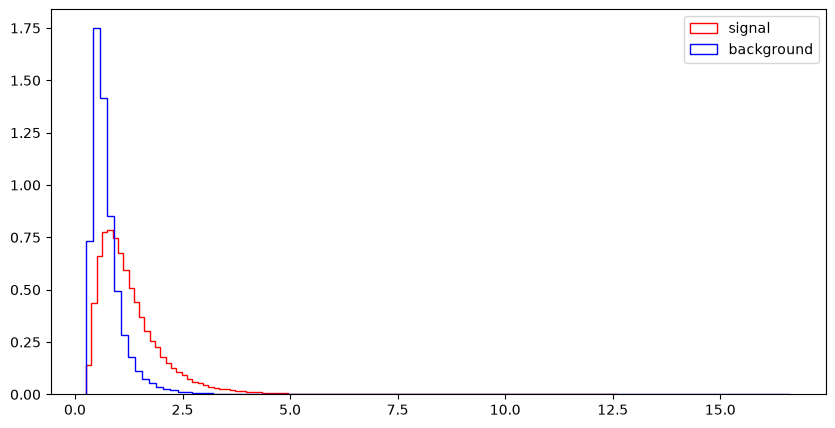

l_1_eta


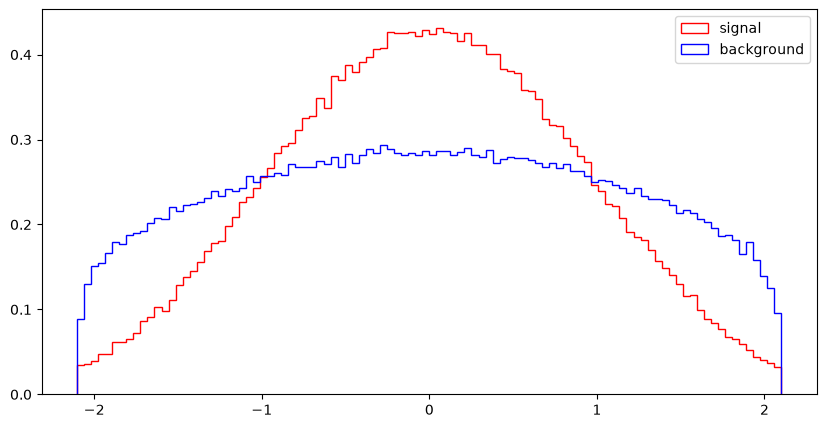

l_1_phi


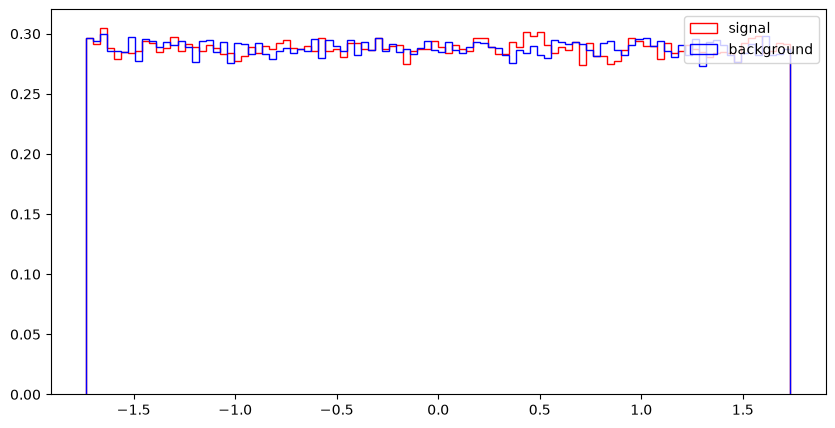

l_2_pT


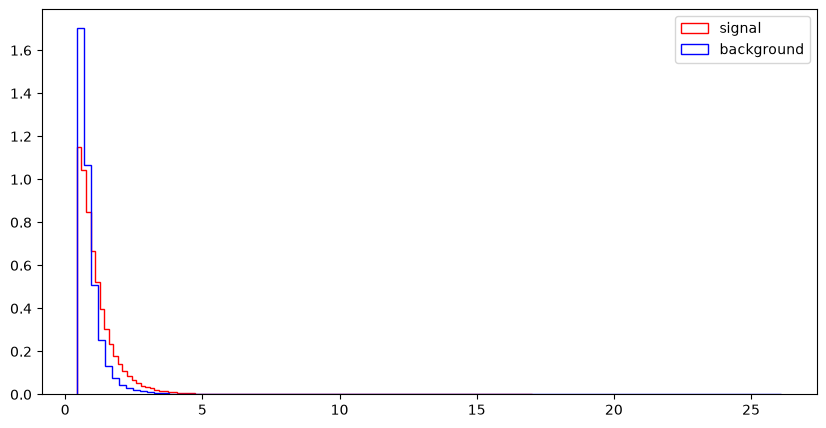

l_2_eta


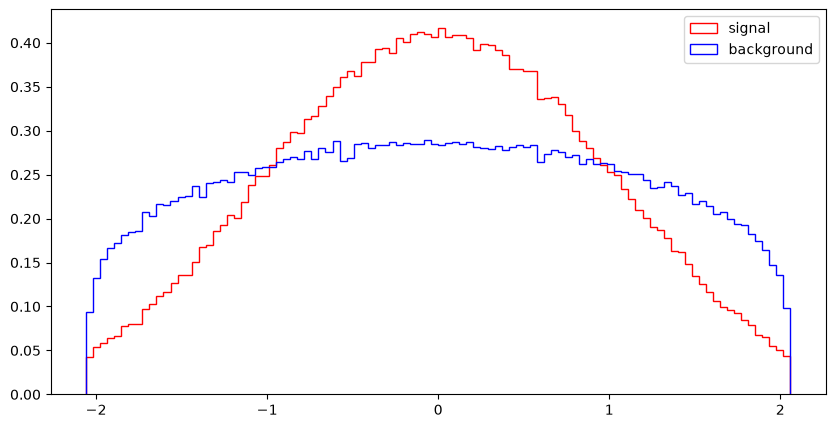

l_2_phi


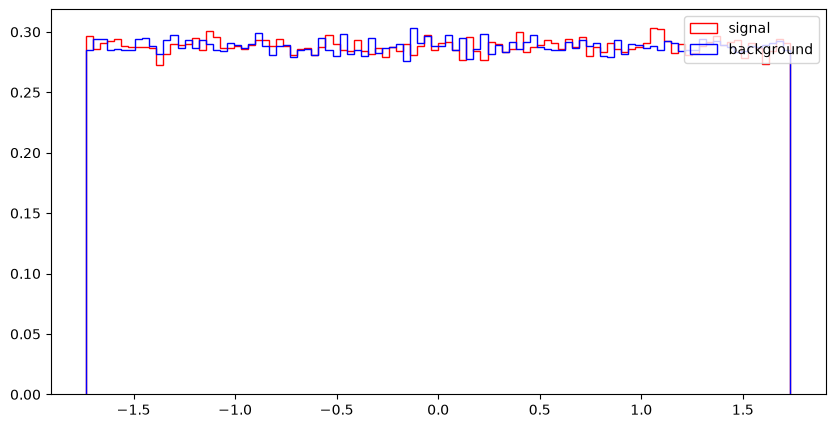

MET


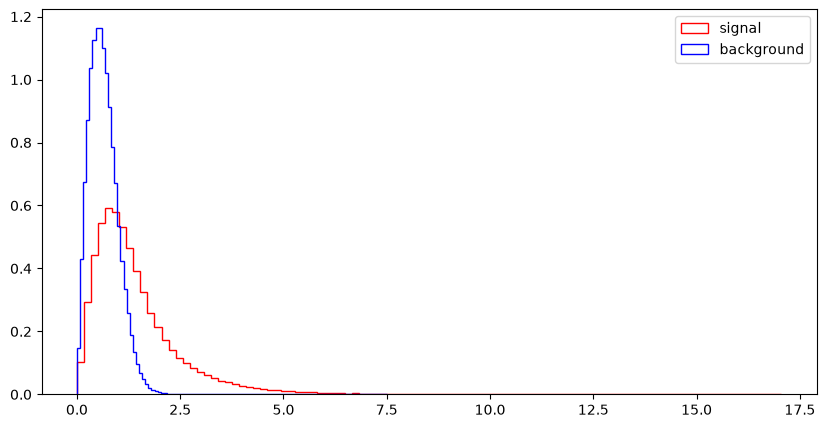

MET_phi


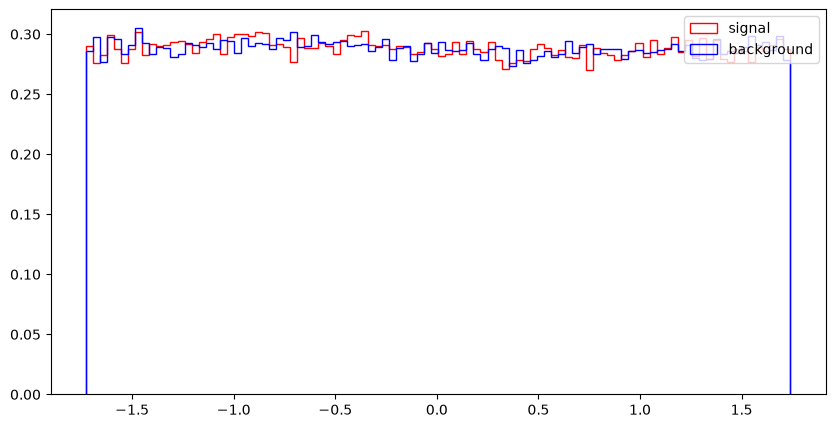

MET_rel


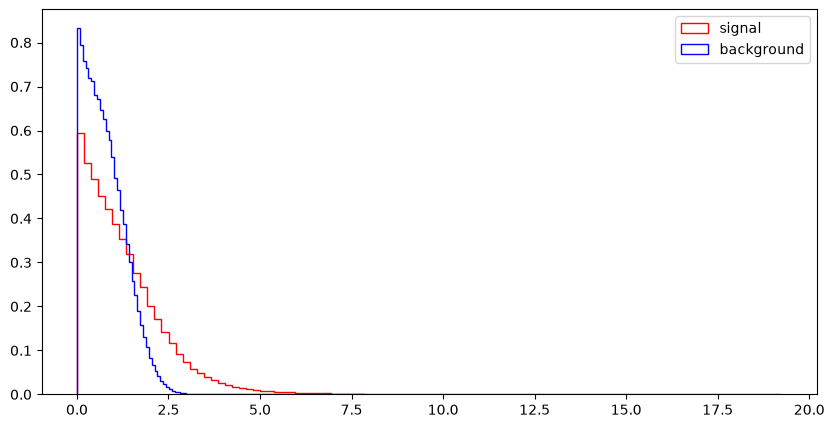

axial_MET


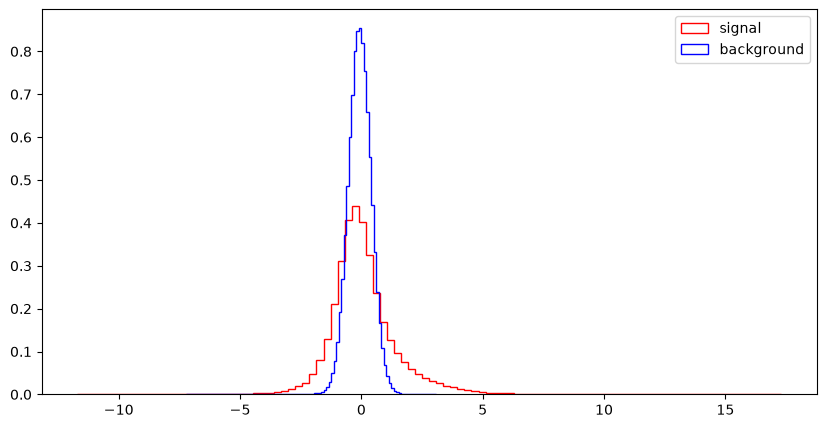

M_R


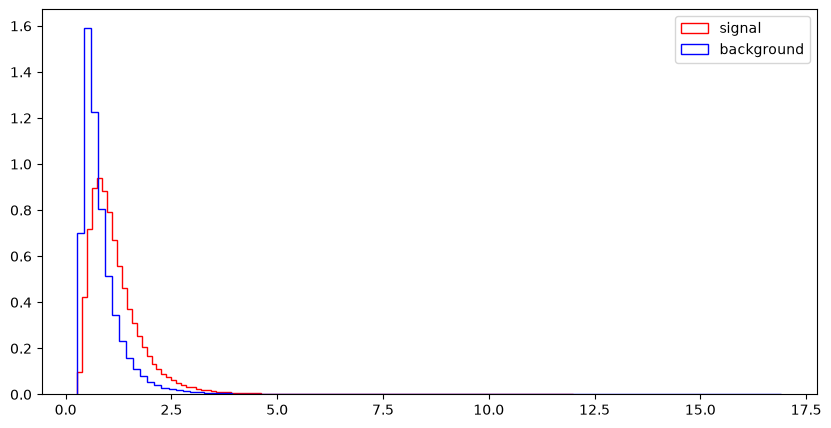

M_TR_2


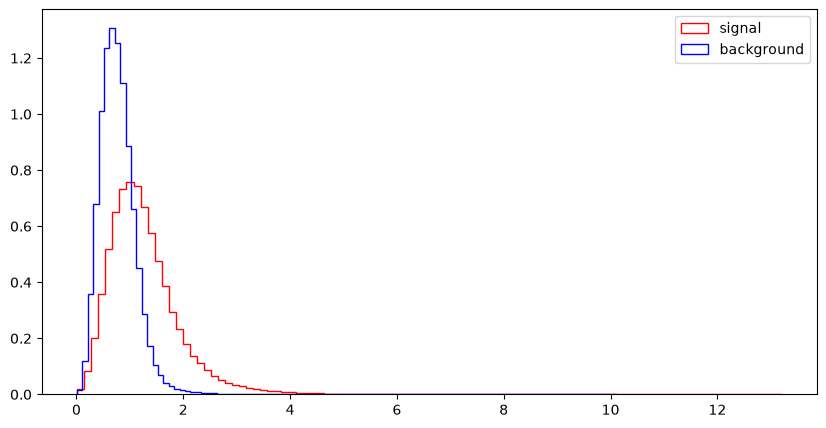

R


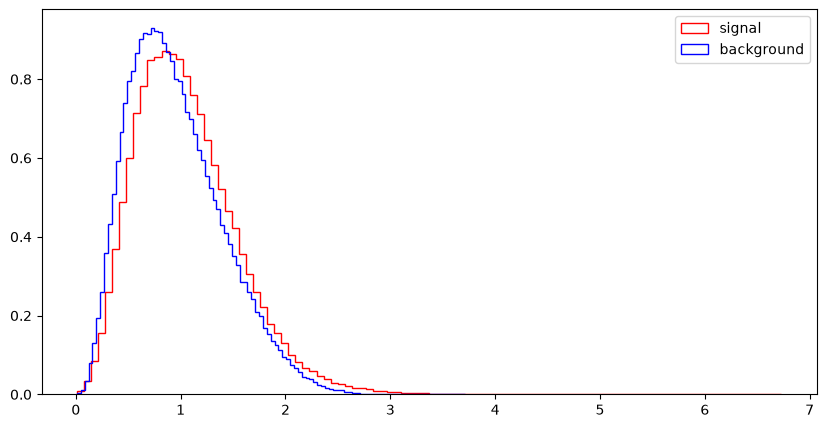

MT2


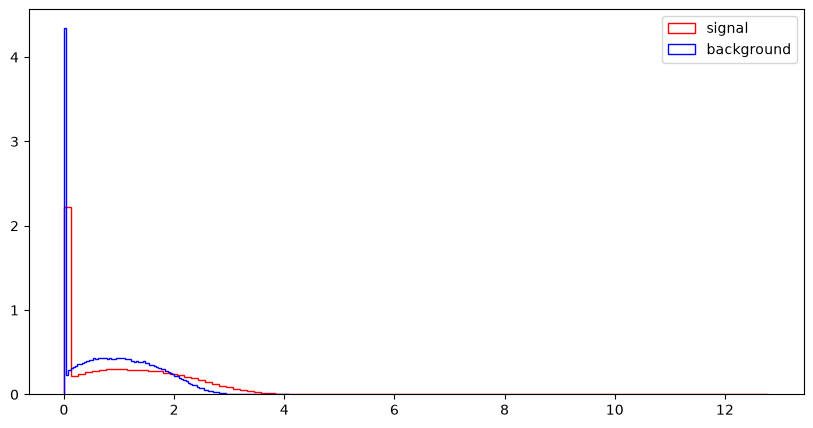

S_R


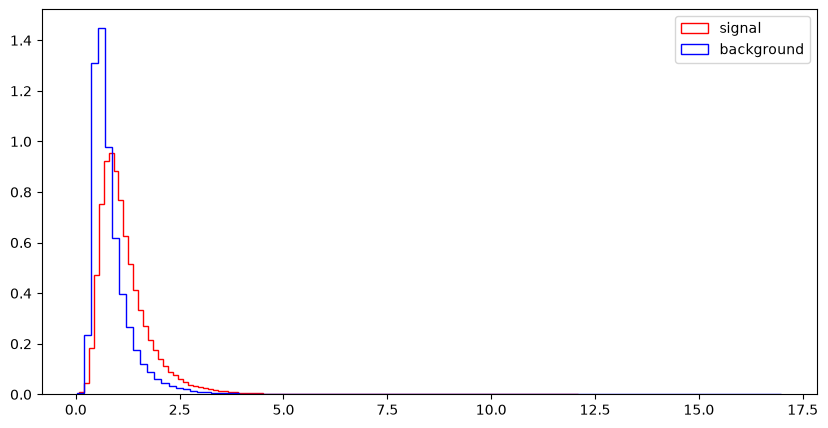

M_Delta_R


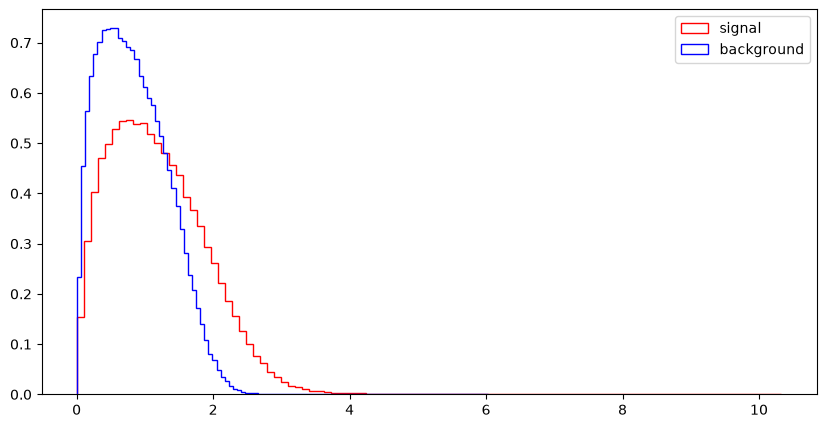

dPhi_r_b


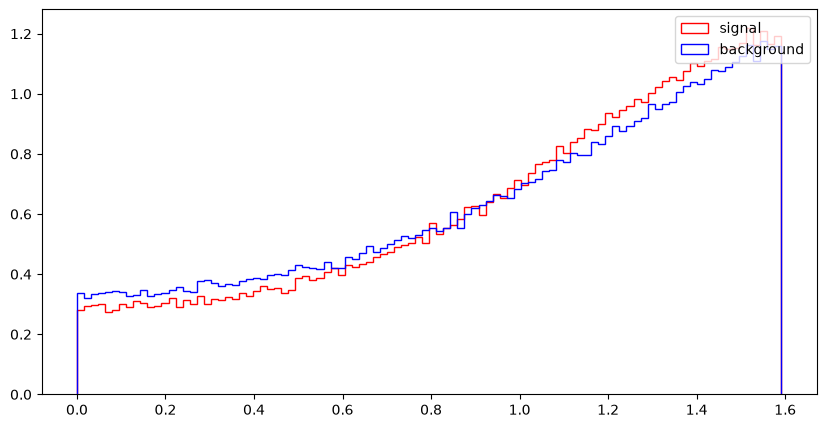

cos_theta_r1


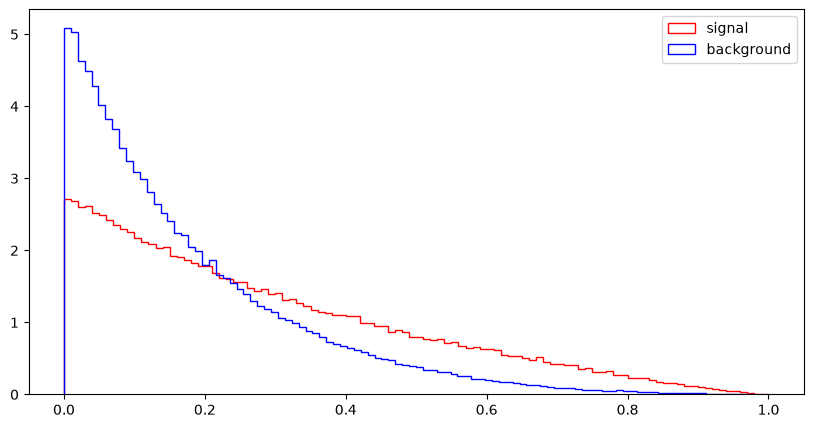

In [21]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

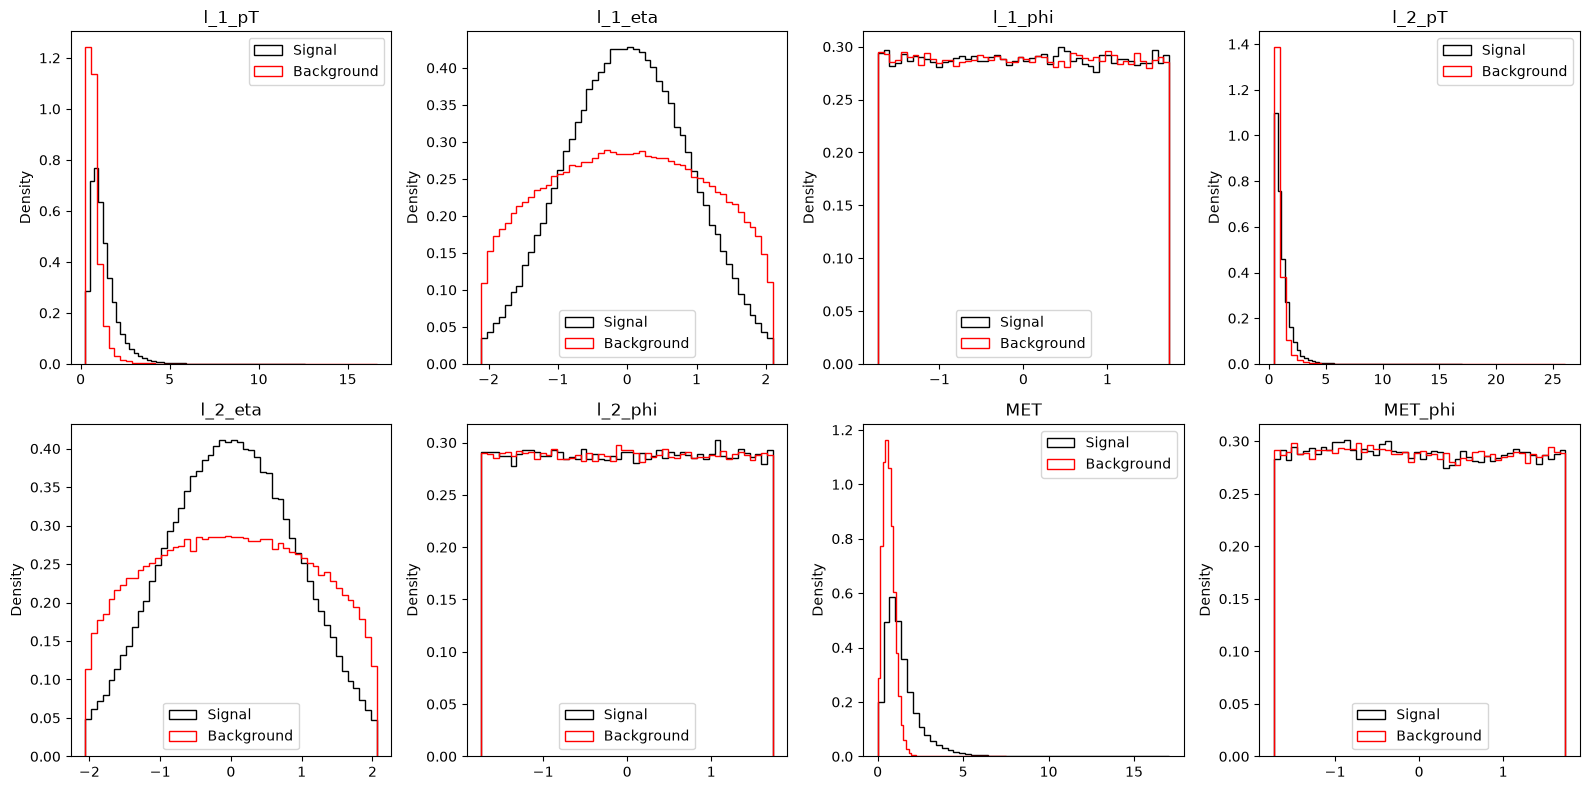

In [22]:
plt.figure(figsize=(16, 8))


for i in range(len(RawNames)):

    var = RawNames[i]

    plt.subplot(2, 4, i +1)

    plt.hist(df_sig[var], bins = 50, density=1,
            histtype="step", color="black", label="Signal" )

    plt.hist(df_bkg[var], bins= 50, density= 1, 
             histtype="step", color="red", label="Background")

    plt.ylabel("Density")
    plt.title(var)
    plt.legend()

plt.tight_layout()
plt.show()



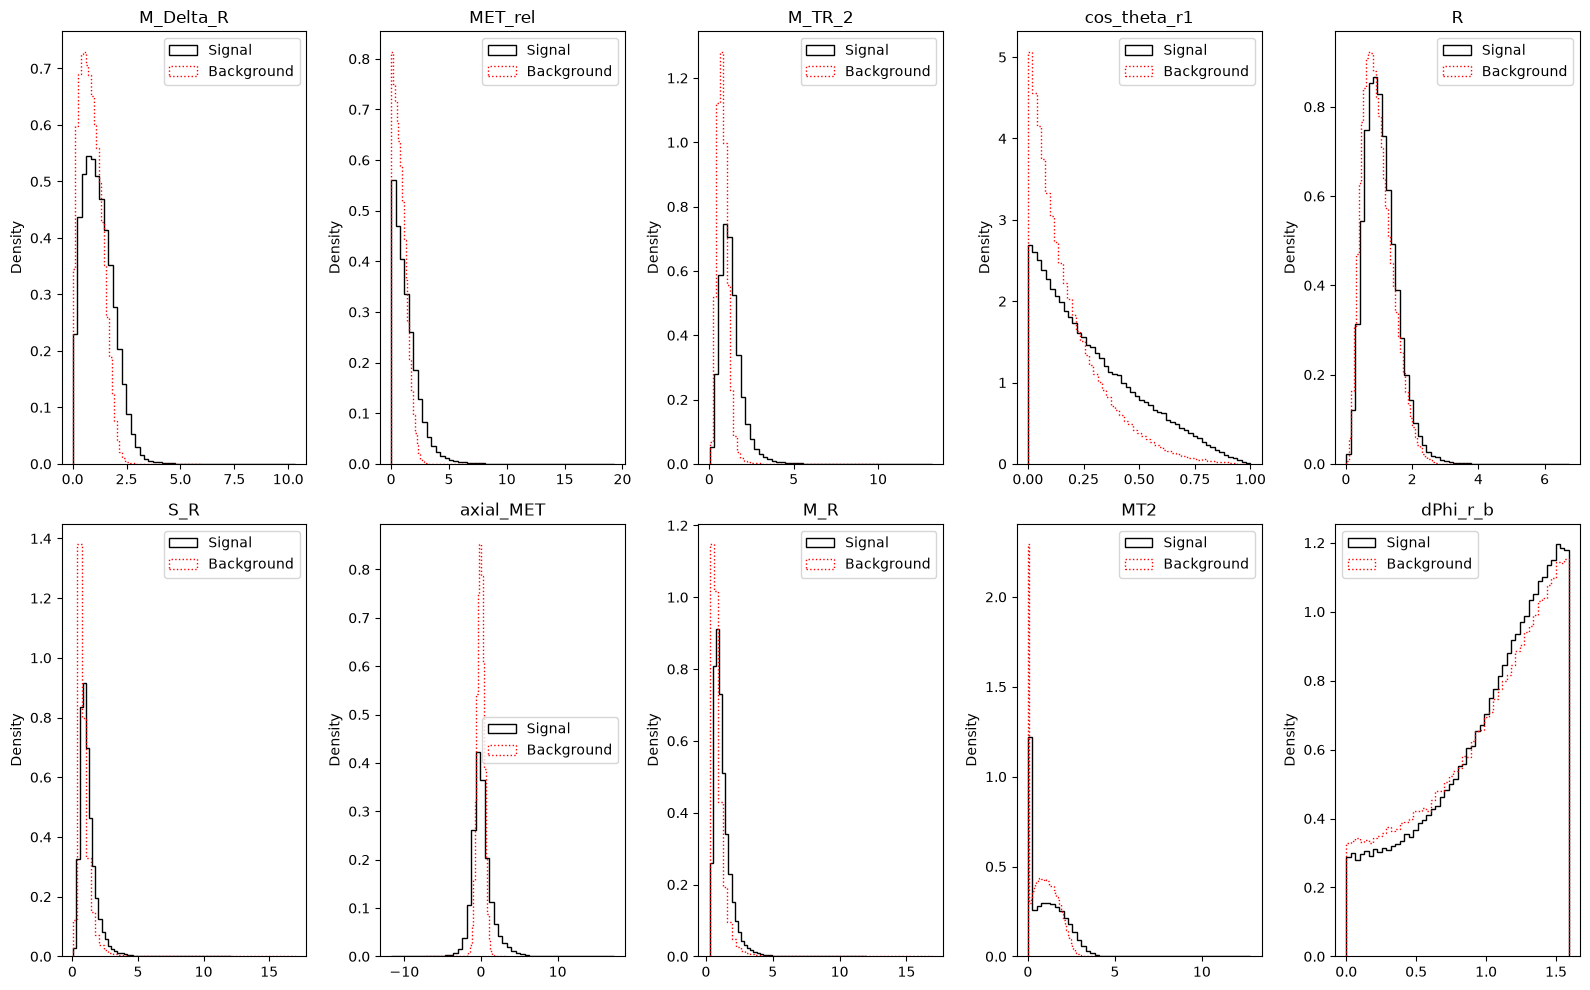

In [23]:
#higher level features


plt.figure(figsize=(16, 10))

for i in range(len(FeatureNames)):
    var = FeatureNames[i]

    plt.subplot(2, 5, i + 1)

    plt.hist(df_sig[var], bins= 50, density=1,
             histtype= "step", color="black", label="Signal")

    plt.hist(df_bkg[var], bins= 50, density= 1,
             histtype="step", color="red",
             linestyle="dotted", label="Background")

    plt.ylabel("Density")

    plt.title(var)
    plt.legend()

plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

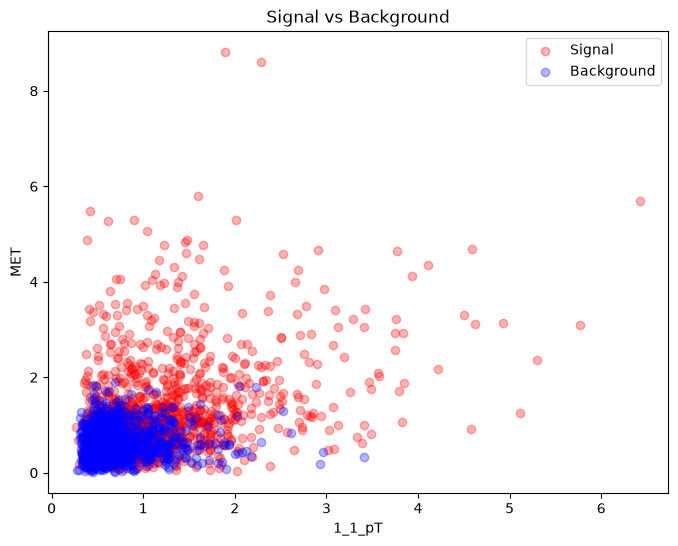

In [24]:
#4.1(a)

plt.figure(figsize=(8, 6))

plt.scatter(df_sig["l_1_pT"][:1000],
            df_sig["MET"][:1000],
            color= "red", alpha=0.3, label ="Signal")

plt.scatter(df_bkg["l_1_pT"][:1000],
            df_bkg["MET"][:1000],
            color= "blue", alpha=0.3, label ="Background")


plt.xlabel("1_1_pT")
plt.ylabel("MET")
plt.title("Signal vs Background")
plt.legend()
plt.show()

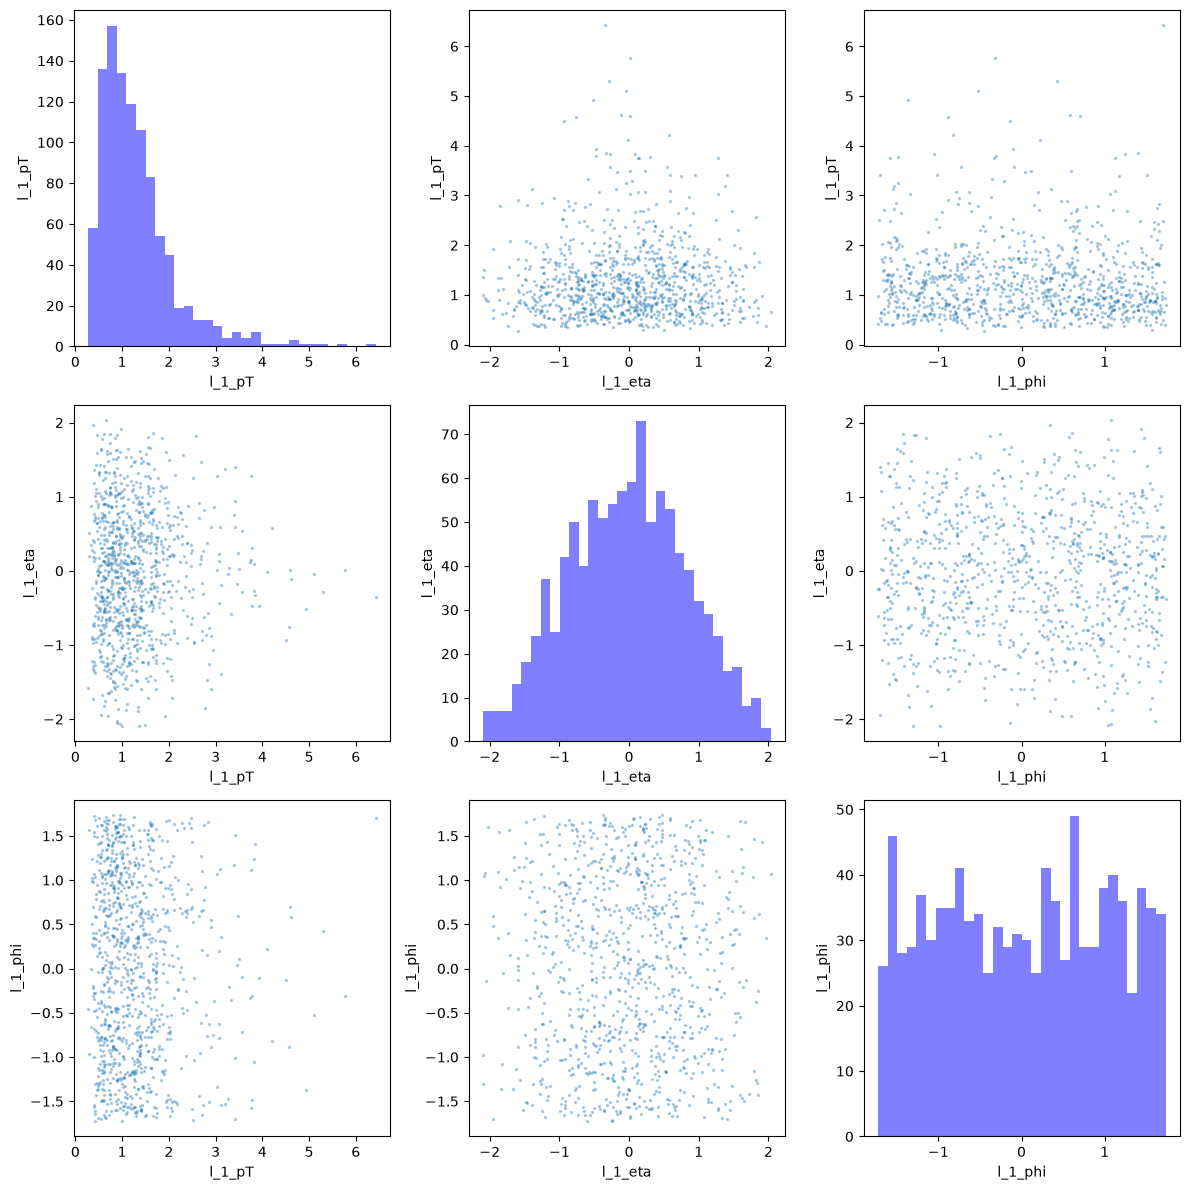

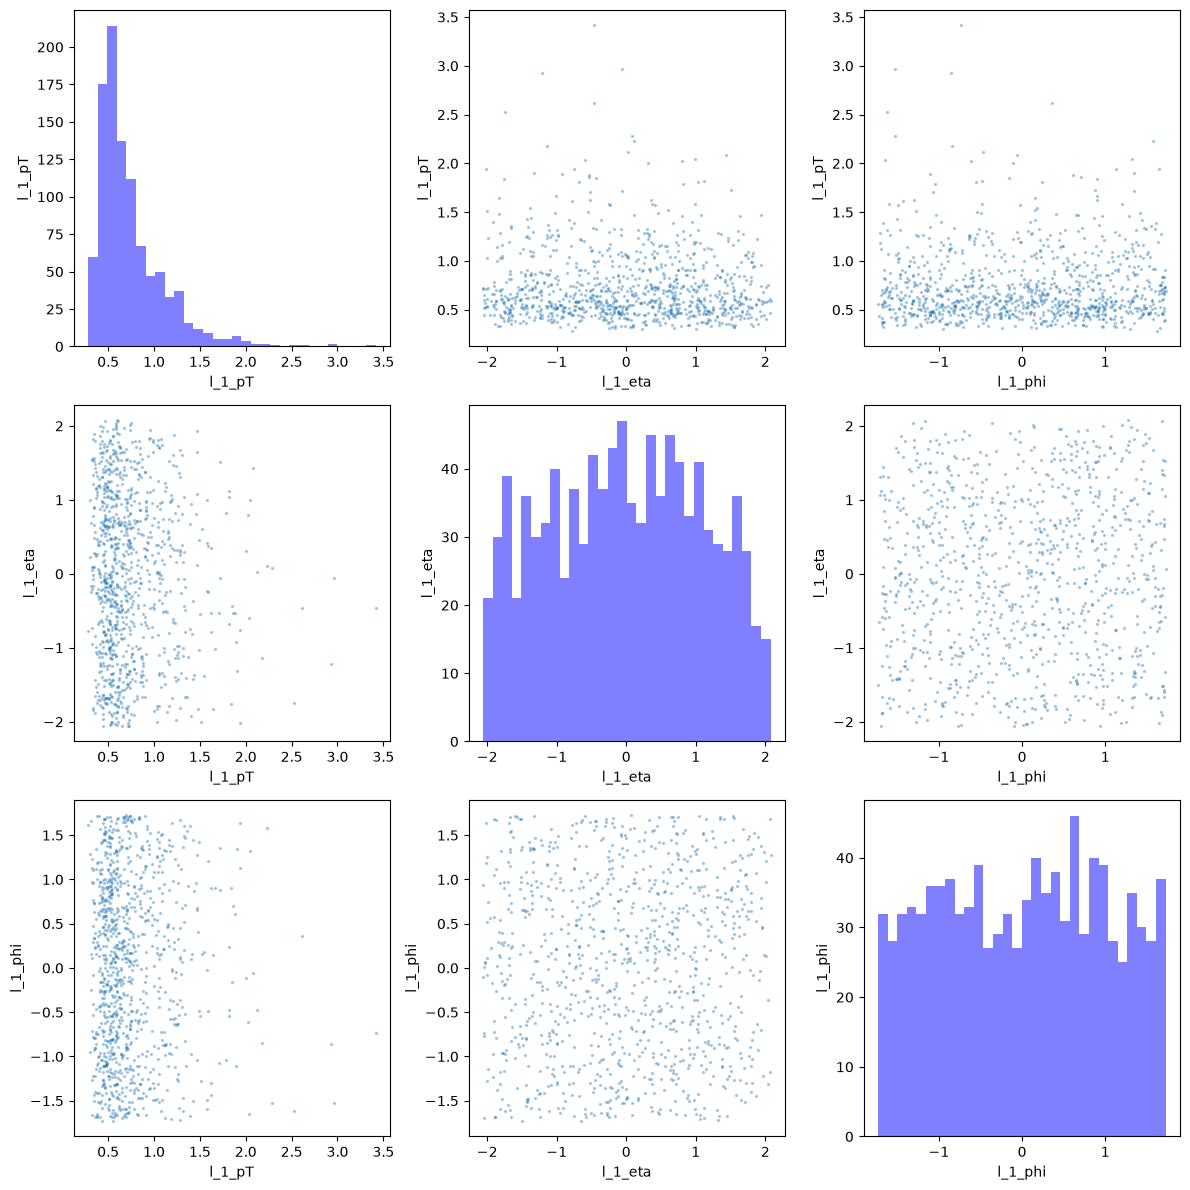

In [25]:
# Exercise 4.1(a) - Pair Plot Function



def pair_plot(data, variables):
    plt.figure(figsize=(12, 12))

    for i in range(len(variables)):
        for j in range(len(variables)):

            plt.subplot(len(variables), len(variables),
                        i * len(variables) + j +1)

            if i == j:
                plt.hist(data[variables[i]], bins= 30,
                         color= "blue", alpha= 0.5)
            else:
                plt.scatter(data[variables[j]],
                            data[variables[i]],
                            s=2, alpha=0.3)
            plt.xlabel(variables[j])
            plt.ylabel(variables[i])

    plt.tight_layout()
    plt.show()

    #tesiting for 3 raw variables
pair_plot(df_sig[:1000], RawNames[:3])

#for background part
pair_plot(df_bkg[:1000], RawNames[:3])

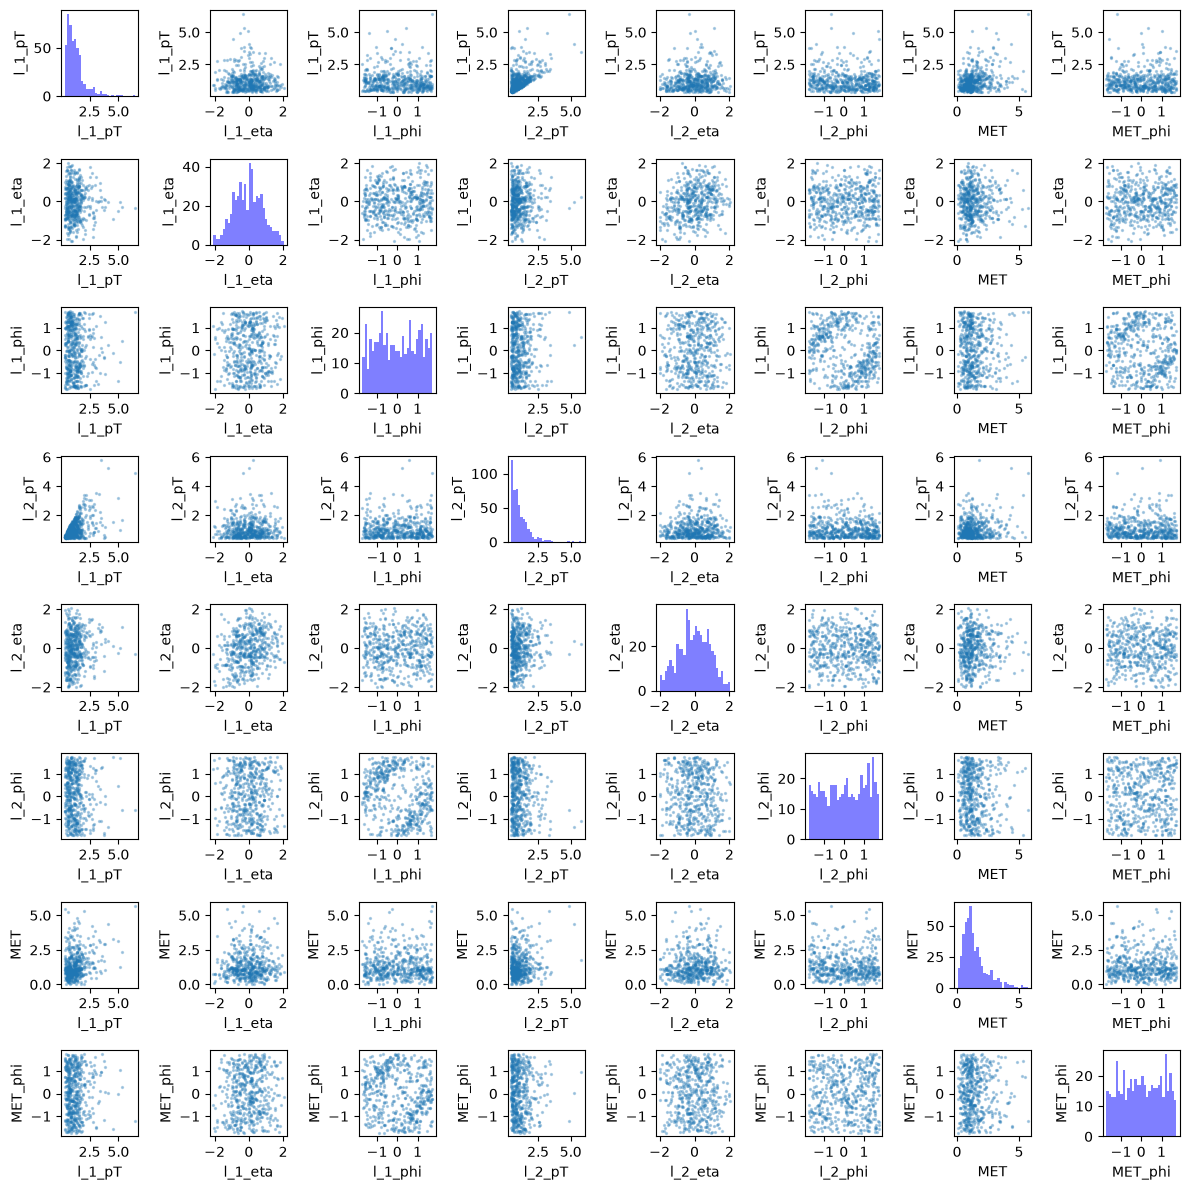

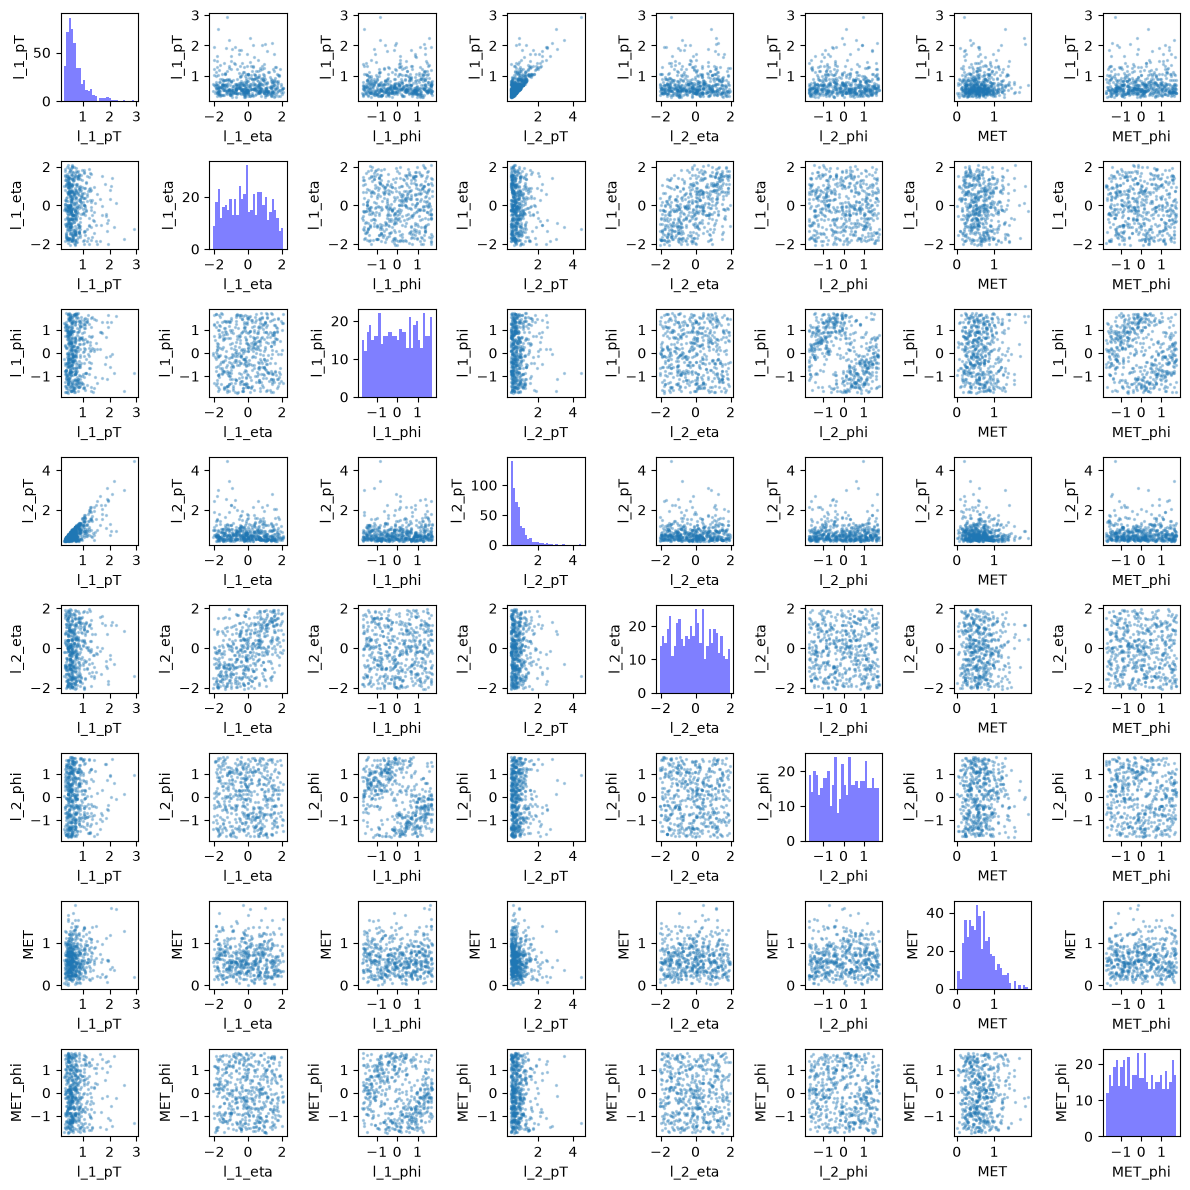

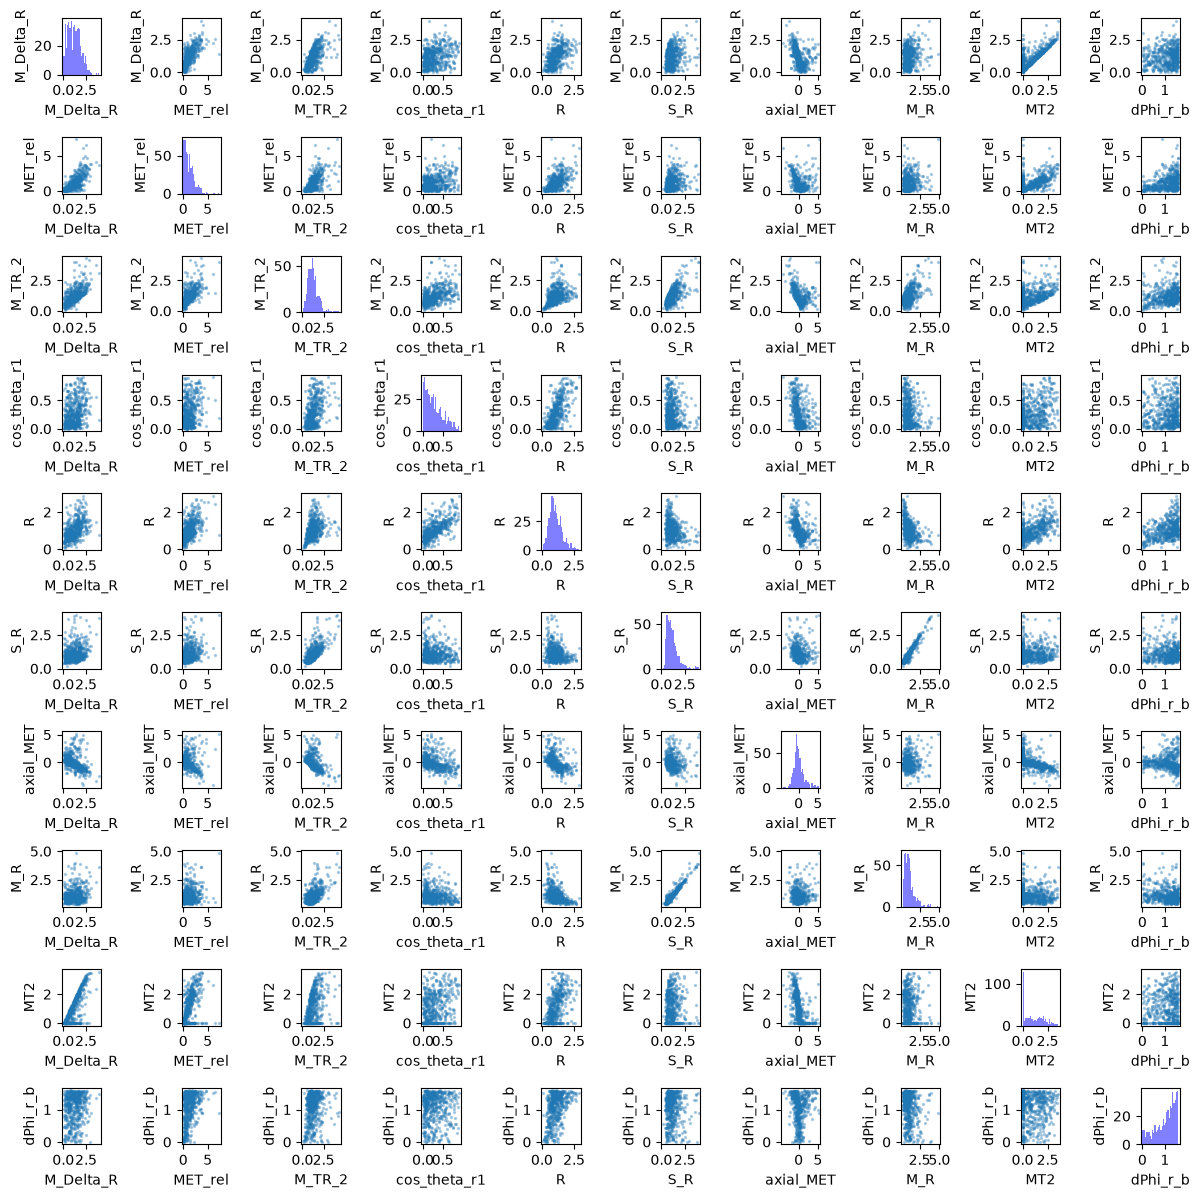

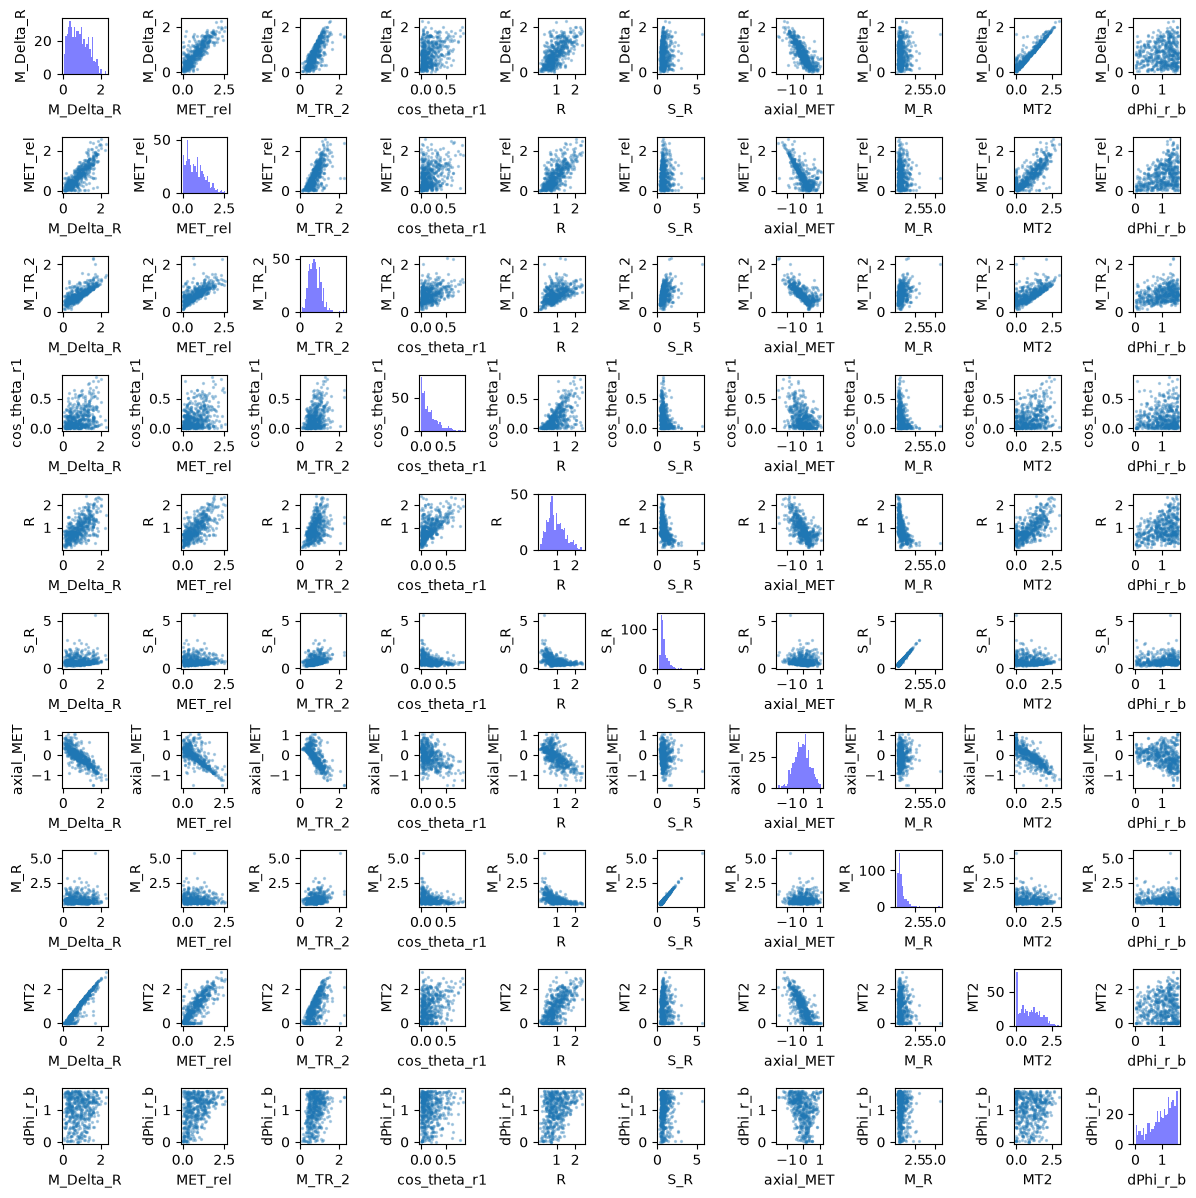

In [26]:
#code for raw vari
pair_plot(df_sig[:500], RawNames)
pair_plot(df_bkg[:500], RawNames)

#for higher level
pair_plot(df_sig[:500], FeatureNames)
pair_plot(df_bkg[:500], FeatureNames)

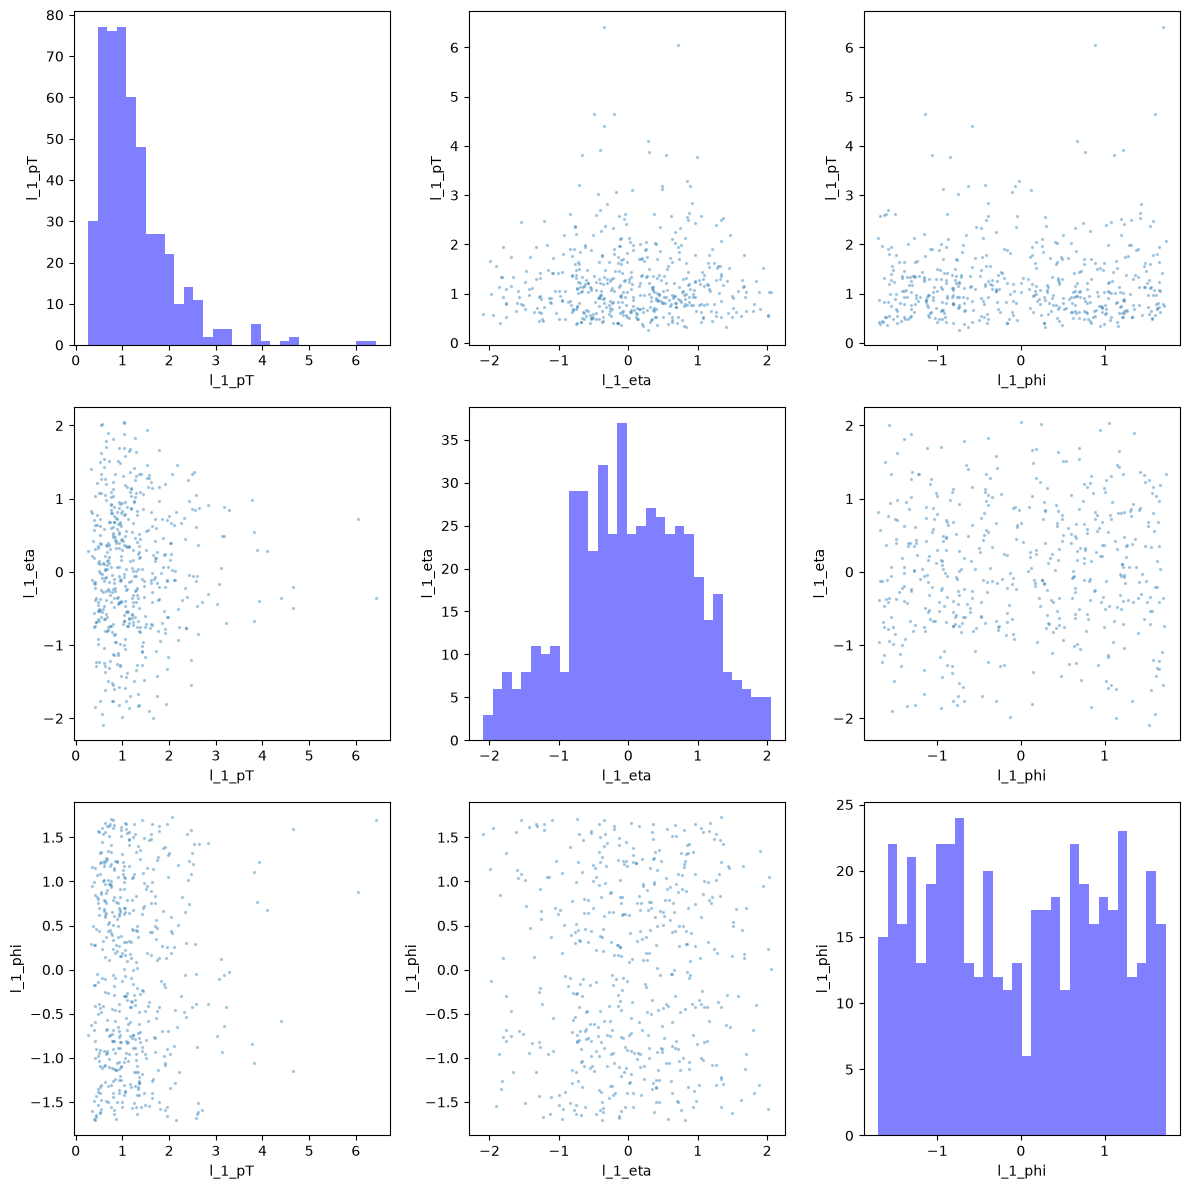

In [27]:
# Exercise 4.1(b) - Faster Pair Plot

def fast_pair_plot(data, variables):

    data = data.sample(n=min(500, len(data)), random_state=42)

    n = len(variables)
    fig, axes = plt.subplots(n, n, figsize=(12, 12))

    for i in range(n):
        for j in range(n):

            ax = axes[i, j]

            if i == j:
                ax.hist(data[variables[i]], bins=30,
                        color="blue", alpha=0.5)

            else:
                ax.scatter(data[variables[j]],
                           data[variables[i]],
                           s=2, alpha=0.3)

            ax.set_xlabel(variables[j])
            ax.set_ylabel(variables[i])

    plt.tight_layout()
    plt.show()


# Test the function
fast_pair_plot(df_sig, RawNames[:3])


4.1b
So for this one i had made my own pair plot function by using 500 random rows instead of using the whole dataset. this had reduced how much of the data that the computer was going to process. Another method of speeding up things would be to use the Numpy feature to analyze and calculate the histogram values before plotting them.

4.1c
Based on the graphs that was provided l_1_pT, MET, cos_theta_r1, and M_Delta_R seem to have the best bvariables for separating the signal from the background. The distributions that we have look different, on the other hand the varriables overlap more often. this is useful for telling the two group apart

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [28]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [29]:
#4.2b


import numpy as np

all_vars = RawNames + FeatureNames

cov_all = np.cov(df[all_vars].values, rowvar=False)
corr_all = np.corrcoef(df[all_vars].values, rowvar=False)

#lower lever

cov_raw = np.cov(df[RawNames].values, rowvar=False)
corr_raw = np.corrcoef(df[RawNames].values, rowvar=False)

#higher value

cov_high = np.cov(df[FeatureNames].values, rowvar=False)
corr_high = np.corrcoef(df[FeatureNames].values, rowvar=False)

print("All observables:", cov_all.shape, corr_all.shape)
print("Low level:", cov_raw.shape, corr_raw.shape)
print("High-level:", cov_high.shape, corr_high.shape)

All observables: (18, 18) (18, 18)
Low level: (8, 8) (8, 8)
High-level: (10, 10) (10, 10)


In [30]:
# Exercise 4.2(c)

import tabulate
from IPython.display import HTML, display

def show_table(matrix, names, title):
    print(title)
    table = []

    for i in range(len(names)):
        row = [names[i]] + list(np.round(matrix[i], 3))
        table.append(row)

    display(HTML(tabulate.tabulate(
        table,
        headers=["Variable"] + names,
        tablefmt="html"
    )))


# All observables
show_table(cov_all, all_vars, "All Variables - Covariance")
show_table(corr_all, all_vars, "All Variables - Correlation")

# Low-level variables
show_table(cov_raw, RawNames, "Low-Level - Covariance")
show_table(corr_raw, RawNames, "Low-Level - Correlation")

# High-level variables
show_table(cov_high, FeatureNames, "High-Level - Covariance")
show_table(corr_high, FeatureNames, "High-Level - Correlation")

All Variables - Covariance


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,0.098,0.287,0.022,-0.06,0.343,-0.01,0.364,-0.012,-0.047
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,0.001,0.001,0,0,0.001,-0.002,0.001,0.001,0.001
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,0.006,-0.001,0.163,-0.028,-0.099,0.322,0.051,0.325,-0.069,-0.004
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,0.001,0,0,0,-0.001,-0.001,-0.001,0.001,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,0.001,0.001,0,0.001,0.001,-0.002,0.001,0.002,-0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.315,0.546,0.365,0.073,0.188,0.166,0.154,0.145,0.155,0.146
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.001,-0.005,-0.001,0,-0,-0.002,-0,-0.001,0,-0.002
M_Delta_R,0.098,-0.001,0.001,0.006,0.001,0.001,0.315,-0.001,0.389,0.415,0.242,0.039,0.165,0.096,-0.233,0.074,0.433,0.042
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.415,0.79,0.302,0.055,0.249,0.082,-0.12,0.044,0.409,0.146


All Variables - Correlation


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.229,0.16,0.723,0.165,-0.186,0.811,-0.014,0.851,-0.021,-0.157
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.002,-0.001,0.002,0.001,-0.001,-0.001,-0.001,0,-0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,0.001,0.001,0.001,0,0.002,-0.002,0.002,0.001,0.002
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,0.014,-0.001,0.43,-0.217,-0.324,0.799,0.078,0.797,-0.123,-0.013
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,0.001,0,0.001,0.001,-0.001,-0.001,-0.001,0.002,-0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,0.002,0.001,0,0.001,0.001,-0.002,0.001,0.003,-0.001
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.579,0.704,0.72,0.425,0.457,0.307,0.176,0.264,0.206,0.383
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.001,-0.005,-0.002,0.001,-0,-0.003,-0,-0.002,0,-0.004
M_Delta_R,0.229,-0.002,0.001,0.014,0.001,0.002,0.579,-0.001,1,0.748,0.668,0.319,0.564,0.249,-0.373,0.189,0.809,0.155
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,0.748,1,0.584,0.316,0.595,0.15,-0.134,0.078,0.535,0.378


Low-Level - Covariance


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


... (2 outputs left out)

High-Level - Covariance


Variable,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
M_Delta_R,0.389,0.415,0.242,0.039,0.165,0.096,-0.233,0.074,0.433,0.042
MET_rel,0.415,0.79,0.302,0.055,0.249,0.082,-0.12,0.044,0.409,0.146
M_TR_2,0.242,0.302,0.338,0.052,0.104,0.228,-0.185,0.21,0.189,0.058
cos_theta_r1,0.039,0.055,0.052,0.039,0.058,-0.01,-0.054,-0.014,0.045,0.009
R,0.165,0.249,0.104,0.058,0.222,-0.083,-0.181,-0.113,0.232,0.087
S_R,0.096,0.082,0.228,-0.01,-0.083,0.382,-0.041,0.38,-0.011,-0.003
axial_MET,-0.233,-0.12,-0.185,-0.054,-0.181,-0.041,1.005,0.017,-0.461,-0.025
M_R,0.074,0.044,0.21,-0.014,-0.113,0.38,0.017,0.392,-0.037,-0.029
MT2,0.433,0.409,0.189,0.045,0.232,-0.011,-0.461,-0.037,0.738,0.021
dPhi_r_b,0.042,0.146,0.058,0.009,0.087,-0.003,-0.025,-0.029,0.021,0.19


High-Level - Correlation


Variable,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
M_Delta_R,1,0.748,0.668,0.319,0.564,0.249,-0.373,0.189,0.809,0.155
MET_rel,0.748,1,0.584,0.316,0.595,0.15,-0.134,0.078,0.535,0.378
M_TR_2,0.668,0.584,1,0.451,0.38,0.635,-0.317,0.577,0.379,0.229
cos_theta_r1,0.319,0.316,0.451,1,0.627,-0.085,-0.272,-0.116,0.264,0.106
R,0.564,0.595,0.38,0.627,1,-0.287,-0.383,-0.383,0.574,0.424
S_R,0.249,0.15,0.635,-0.085,-0.287,1,-0.067,0.981,-0.021,-0.013
axial_MET,-0.373,-0.134,-0.317,-0.272,-0.383,-0.067,1,0.027,-0.535,-0.057
M_R,0.189,0.078,0.577,-0.116,-0.383,0.981,0.027,1,-0.068,-0.106
MT2,0.809,0.535,0.379,0.264,0.574,-0.021,-0.535,-0.068,1,0.056
dPhi_r_b,0.155,0.378,0.229,0.106,0.424,-0.013,-0.057,-0.106,0.056,1


So for part c i had chat help me out since i was having trouble with the methods of doing it in theory 

In [ ]:
# Exercise 4.2(d)



def matrix_report(data, names, title):
    
    covariance = np.cov(data[names].values, rowvar=False)
    correlation = np.corrcoef(data[names].values, rowvar=False)

    show_table(covariance, names, title + " - Covariance")
    show_table(correlation, names, title + " - Correlation")


matrix_report(df, all_vars, "All Variables")
matrix_report(df, RawNames, "Low-Level Variables")
matrix_report(df, FeatureNames, "High-Level Variables")
  

All Variables - Covariance


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,0.098,0.287,0.022,-0.06,0.343,-0.01,0.364,-0.012,-0.047
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,0.001,0.001,0,0,0.001,-0.002,0.001,0.001,0.001
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,0.006,-0.001,0.163,-0.028,-0.099,0.322,0.051,0.325,-0.069,-0.004
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,0.001,0,0,0,-0.001,-0.001,-0.001,0.001,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,0.001,0.001,0,0.001,0.001,-0.002,0.001,0.002,-0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.315,0.546,0.365,0.073,0.188,0.166,0.154,0.145,0.155,0.146
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.001,-0.005,-0.001,0,-0,-0.002,-0,-0.001,0,-0.002
M_Delta_R,0.098,-0.001,0.001,0.006,0.001,0.001,0.315,-0.001,0.389,0.415,0.242,0.039,0.165,0.096,-0.233,0.074,0.433,0.042
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.415,0.79,0.302,0.055,0.249,0.082,-0.12,0.044,0.409,0.146


All Variables - Correlation


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.229,0.16,0.723,0.165,-0.186,0.811,-0.014,0.851,-0.021,-0.157
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.002,-0.001,0.002,0.001,-0.001,-0.001,-0.001,0,-0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,0.001,0.001,0.001,0,0.002,-0.002,0.002,0.001,0.002
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,0.014,-0.001,0.43,-0.217,-0.324,0.799,0.078,0.797,-0.123,-0.013
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,0.001,0,0.001,0.001,-0.001,-0.001,-0.001,0.002,-0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,0.002,0.001,0,0.001,0.001,-0.002,0.001,0.003,-0.001
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.579,0.704,0.72,0.425,0.457,0.307,0.176,0.264,0.206,0.383
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.001,-0.005,-0.002,0.001,-0,-0.003,-0,-0.002,0,-0.004
M_Delta_R,0.229,-0.002,0.001,0.014,0.001,0.002,0.579,-0.001,1,0.748,0.668,0.319,0.564,0.249,-0.373,0.189,0.809,0.155
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,0.748,1,0.584,0.316,0.595,0.15,-0.134,0.078,0.535,0.378


Low-Level Variables - Covariance


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


... (2 outputs left out)

High-Level Variables - Covariance


Variable,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
M_Delta_R,0.389,0.415,0.242,0.039,0.165,0.096,-0.233,0.074,0.433,0.042
MET_rel,0.415,0.79,0.302,0.055,0.249,0.082,-0.12,0.044,0.409,0.146
M_TR_2,0.242,0.302,0.338,0.052,0.104,0.228,-0.185,0.21,0.189,0.058
cos_theta_r1,0.039,0.055,0.052,0.039,0.058,-0.01,-0.054,-0.014,0.045,0.009
R,0.165,0.249,0.104,0.058,0.222,-0.083,-0.181,-0.113,0.232,0.087
S_R,0.096,0.082,0.228,-0.01,-0.083,0.382,-0.041,0.38,-0.011,-0.003
axial_MET,-0.233,-0.12,-0.185,-0.054,-0.181,-0.041,1.005,0.017,-0.461,-0.025
M_R,0.074,0.044,0.21,-0.014,-0.113,0.38,0.017,0.392,-0.037,-0.029
MT2,0.433,0.409,0.189,0.045,0.232,-0.011,-0.461,-0.037,0.738,0.021
dPhi_r_b,0.042,0.146,0.058,0.009,0.087,-0.003,-0.025,-0.029,0.021,0.19


High-Level Variables - Correlation


Variable,M_Delta_R,MET_rel,M_TR_2,cos_theta_r1,R,S_R,axial_MET,M_R,MT2,dPhi_r_b
M_Delta_R,1,0.748,0.668,0.319,0.564,0.249,-0.373,0.189,0.809,0.155
MET_rel,0.748,1,0.584,0.316,0.595,0.15,-0.134,0.078,0.535,0.378
M_TR_2,0.668,0.584,1,0.451,0.38,0.635,-0.317,0.577,0.379,0.229
cos_theta_r1,0.319,0.316,0.451,1,0.627,-0.085,-0.272,-0.116,0.264,0.106
R,0.564,0.595,0.38,0.627,1,-0.287,-0.383,-0.383,0.574,0.424
S_R,0.249,0.15,0.635,-0.085,-0.287,1,-0.067,0.981,-0.021,-0.013
axial_MET,-0.373,-0.134,-0.317,-0.272,-0.383,-0.067,1,0.027,-0.535,-0.057
M_R,0.189,0.078,0.577,-0.116,-0.383,0.981,0.027,1,-0.068,-0.106
MT2,0.809,0.535,0.379,0.264,0.574,-0.021,-0.535,-0.068,1,0.056
dPhi_r_b,0.155,0.378,0.229,0.106,0.424,-0.013,-0.057,-0.106,0.056,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [33]:
#5.1


import numpy as np
import matplotlib.pyplot as plt

#combine all the 18 vari into a list
variables = RawNames + FeatureNames 

sig = df_sig.sample(n=min(20000, len(df_sig)), random_state=42)
bkg = df_bkg.sample(n=min(20000, len(df_bkg)), random_state=42)

#dictonaires for storing results
rules = {}
cut_values= {}
efficiencies= {}


# calculate the fraction of events passing a cut
def get_efficiency(values, cuts, rule, mu):
    values = np.sort(values)

    if rule >= 3:
        values = np.sort(np.abs(values - mu))

    counts = np.searchsorted(values, cuts, side="right")


    if rule == 1 or rule == 3:
        return 1 - counts / len(values)
    else:
        return counts / len(values)


for var in variables:
    s = sig[var].to_numpy()
    b = bkg[var].to_numpy()

    mu = np.mean(np.concatenate([s, b]))

    best_score =-1

    for rule in [1, 2, 3, 4]:

        if rule <= 2:
            values = np.concatenate([s,b])
        else:
            values = np.abs(np.concatenate([s,b]) - mu)

        cuts = np.linspace(np.percentile(values, 1),
                           np.percentile(values, 99), 100)

        tpr = get_efficiency(s, cuts, rule, mu)
        fpr = get_efficiency(b, cuts, rule, mu)

        score = np.max(tpr - fpr)

        if score > best_score:
            best_score = score
            rules[var] = rule
            cut_values[var] = cuts
            efficiencies[var] = (tpr, fpr)

rule_names = {
    1: "x > xc",
    2: "x < xc",
    3: "|x - mu| > xc",
    4: "|x - mu| < xc"
    }

for var in variables:
    print(var, ":", rule_names[rules[var]])


l_1_pT : x > xc
l_1_eta : |x - mu| < xc
l_1_phi : |x - mu| < xc
l_2_pT : x > xc
l_2_eta : |x - mu| < xc
l_2_phi : |x - mu| > xc
MET : x > xc
MET_phi : |x - mu| < xc
M_Delta_R : x > xc
MET_rel : x > xc
M_TR_2 : x > xc
cos_theta_r1 : x > xc
R : x > xc
S_R : x > xc
axial_MET : |x - mu| > xc
M_R : x > xc
MT2 : |x - mu| > xc
dPhi_r_b : x > xc


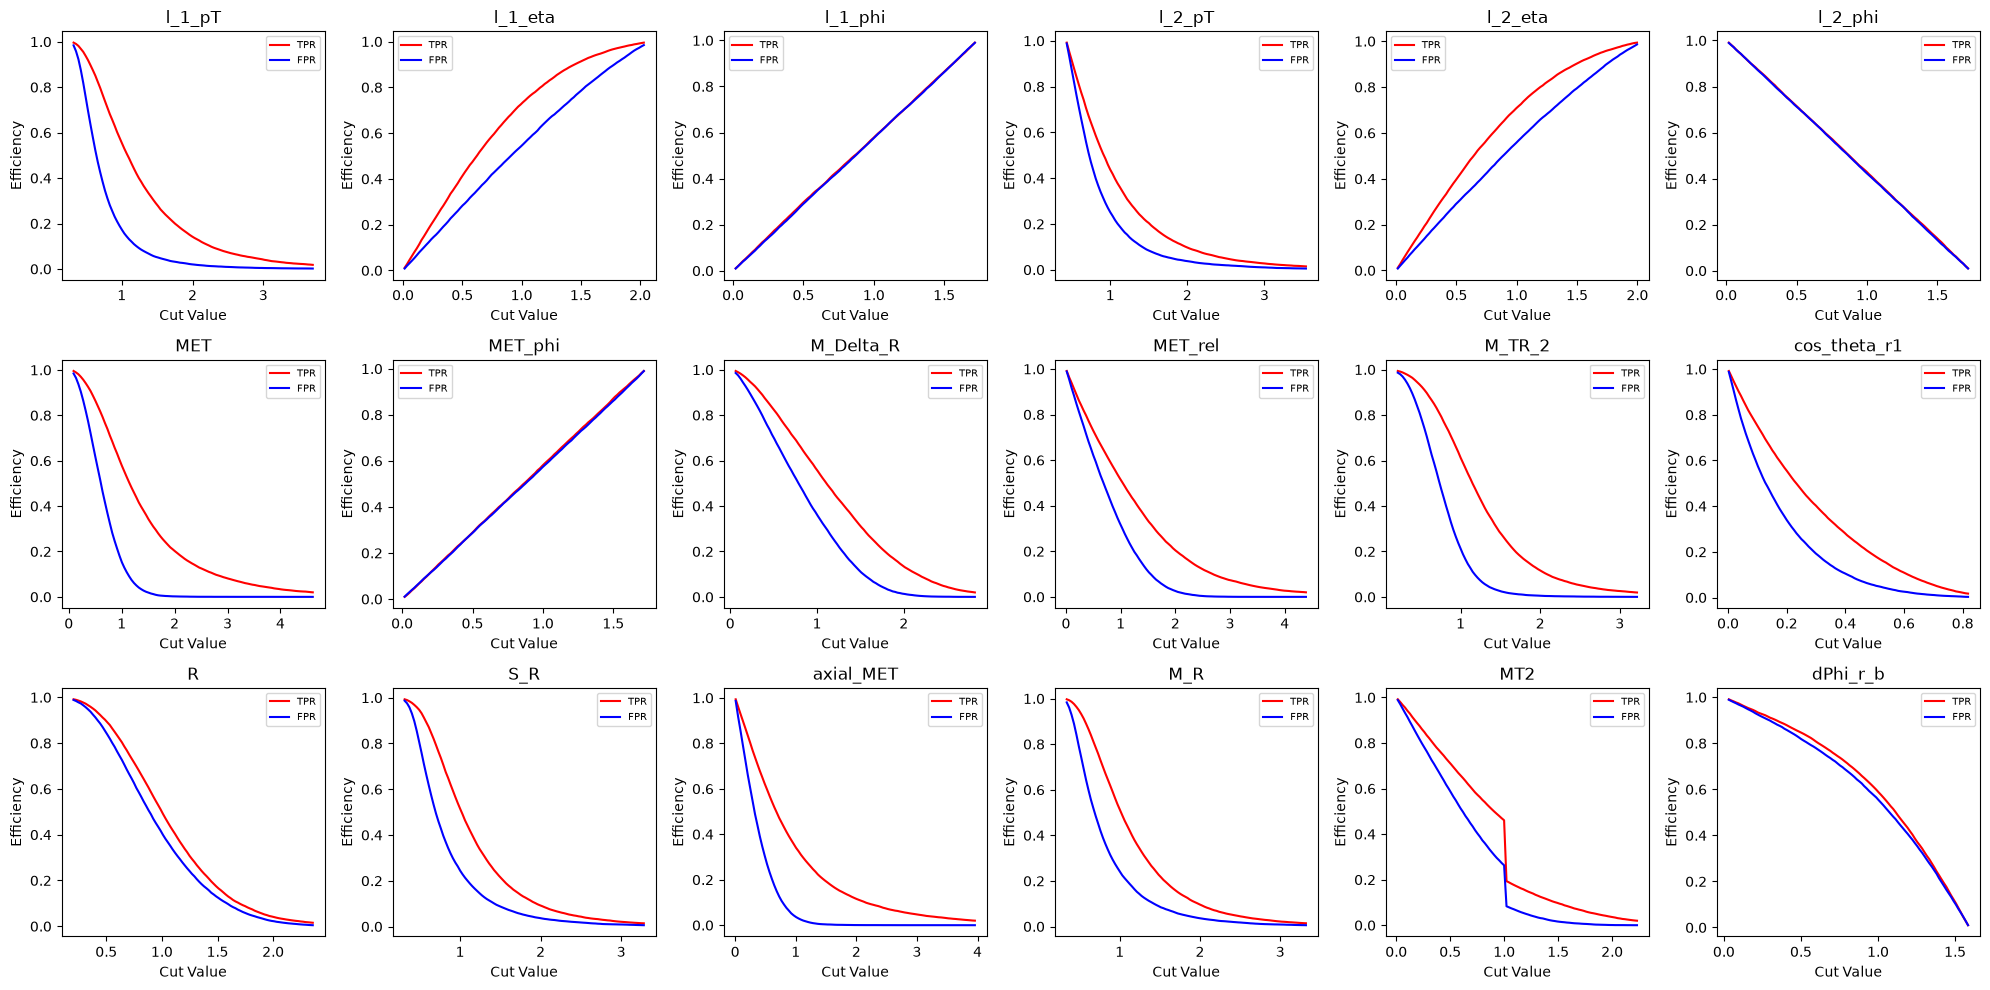

In [34]:

# Exercise 5.2 - Signal and Background Efficiency

# Create 18 graph spaces arranged in 3 rows and 6 columns
fig, axes = plt.subplots(3, 6, figsize=(20, 10))

# Go through every variable and its position
for i, var in enumerate(variables):

    # Select the graph we want to draw on
    ax = axes.flat[i]

    # Get the cutoff values saved in Exercise 5.1
    cuts = cut_values[var]

    # Get the signal and background efficiencies
    tpr, fpr = efficiencies[var]

    # Draw the signal efficiency line in red
    ax.plot(cuts, tpr, color="red", label="TPR")

    # Draw the background efficiency line in blue
    ax.plot(cuts, fpr, color="blue", label="FPR")

    # Give each graph a title using its variable name
    ax.set_title(var)

    # Label the horizontal and vertical axes
    ax.set_xlabel("Cut Value")
    ax.set_ylabel("Efficiency")

    # Show which line represents TPR and FPR
    ax.legend(fontsize=7)

# Fix the spacing between graphs
plt.tight_layout()

# Display all 18 graphs
plt.show()


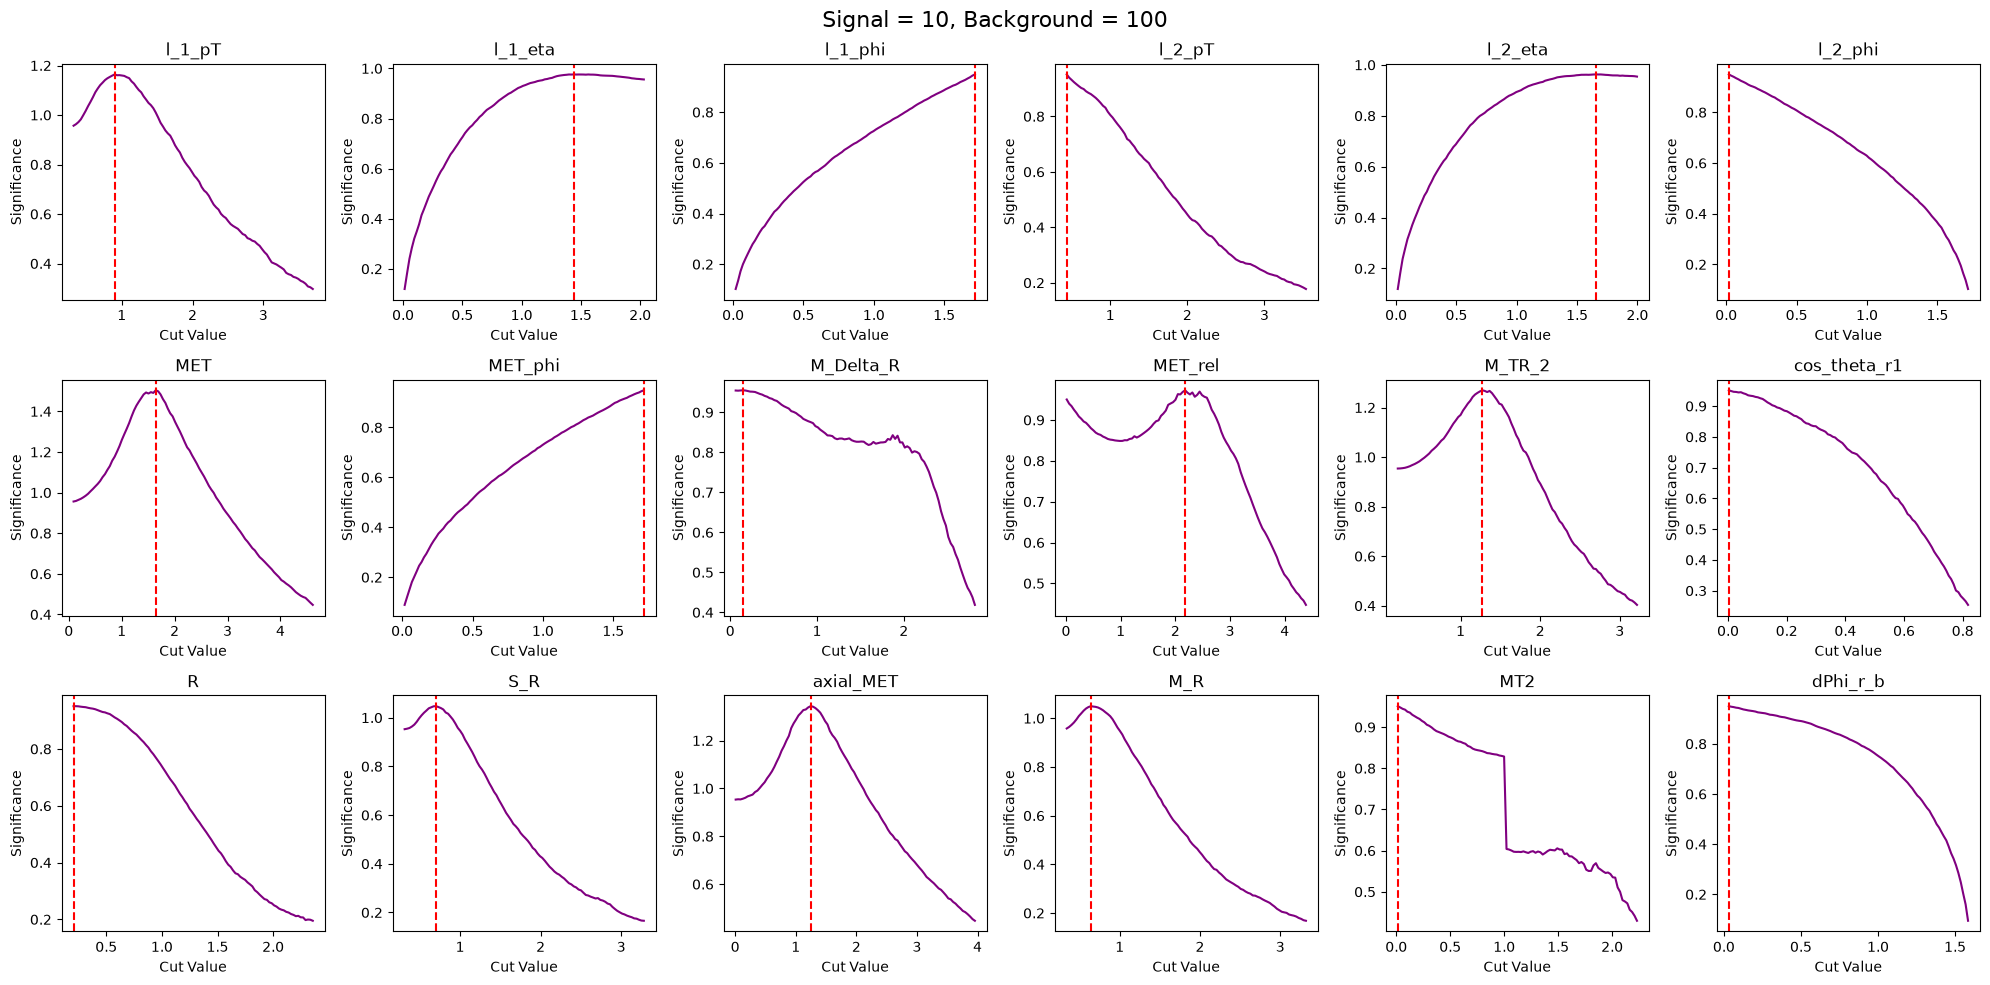

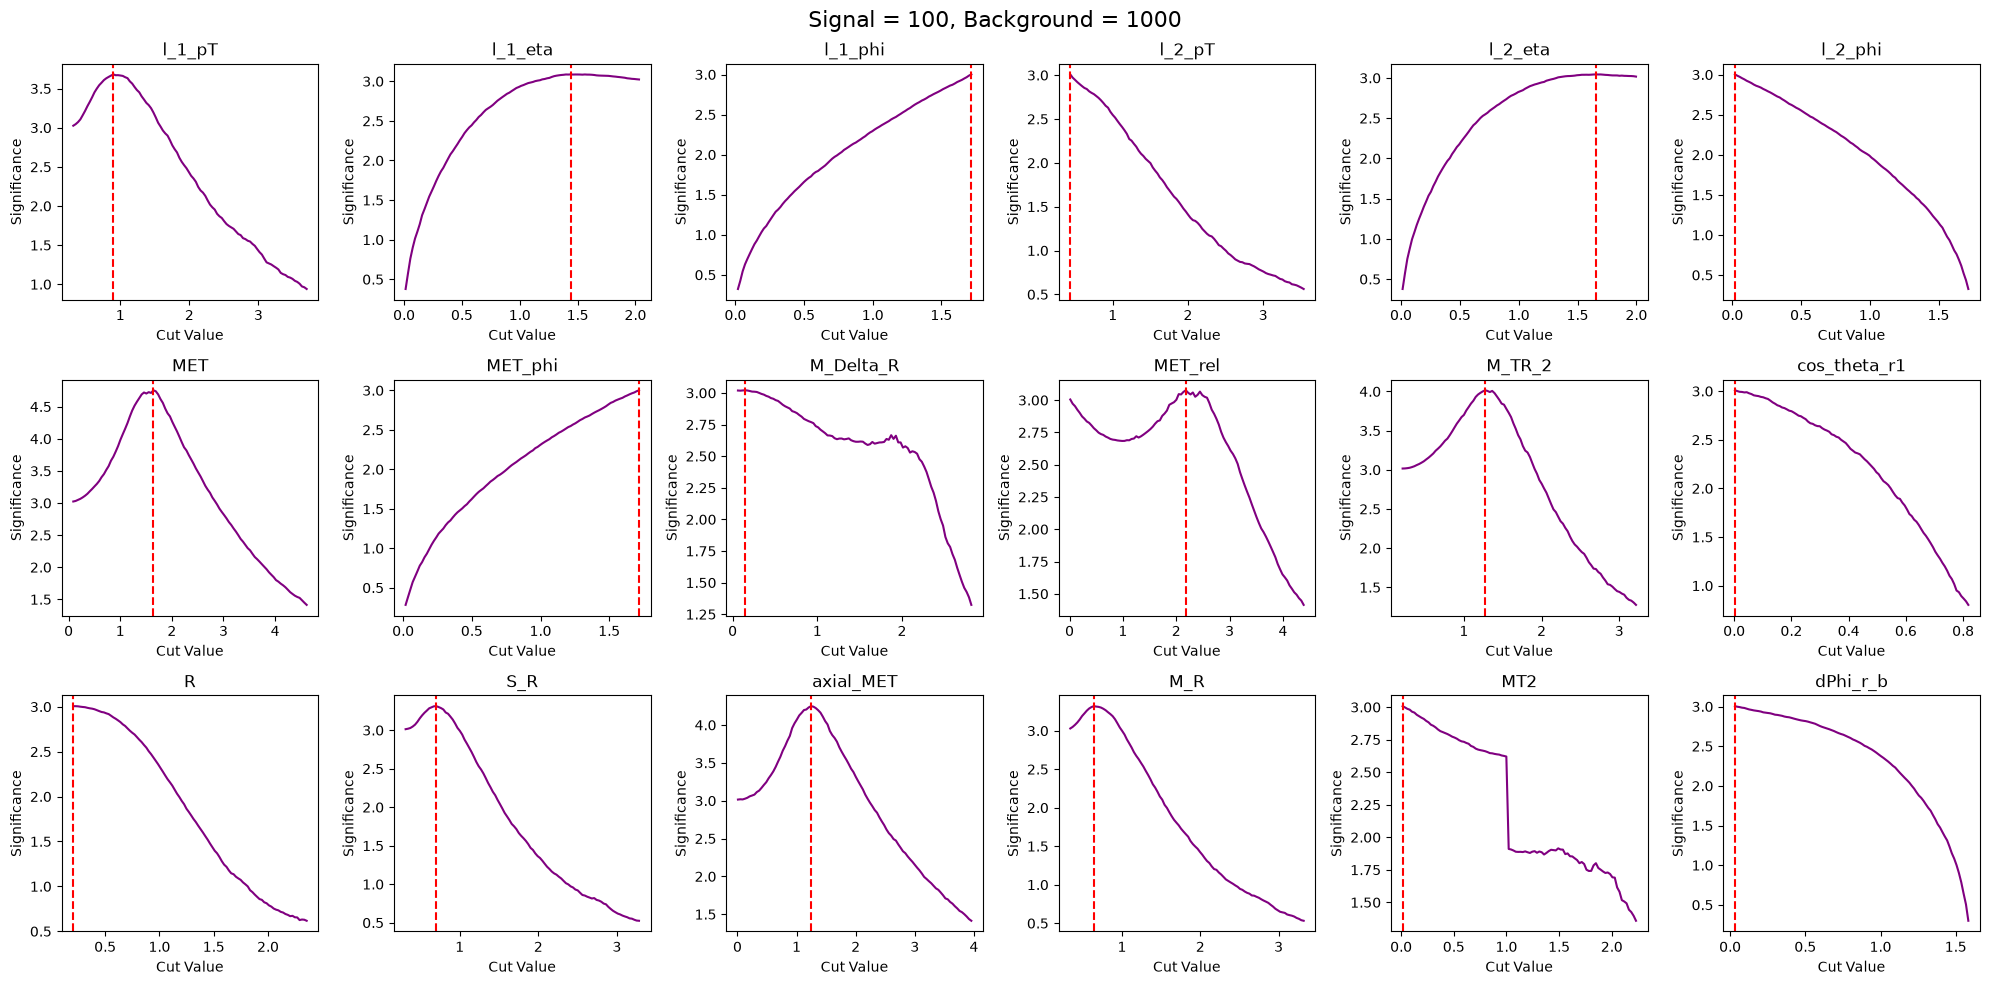

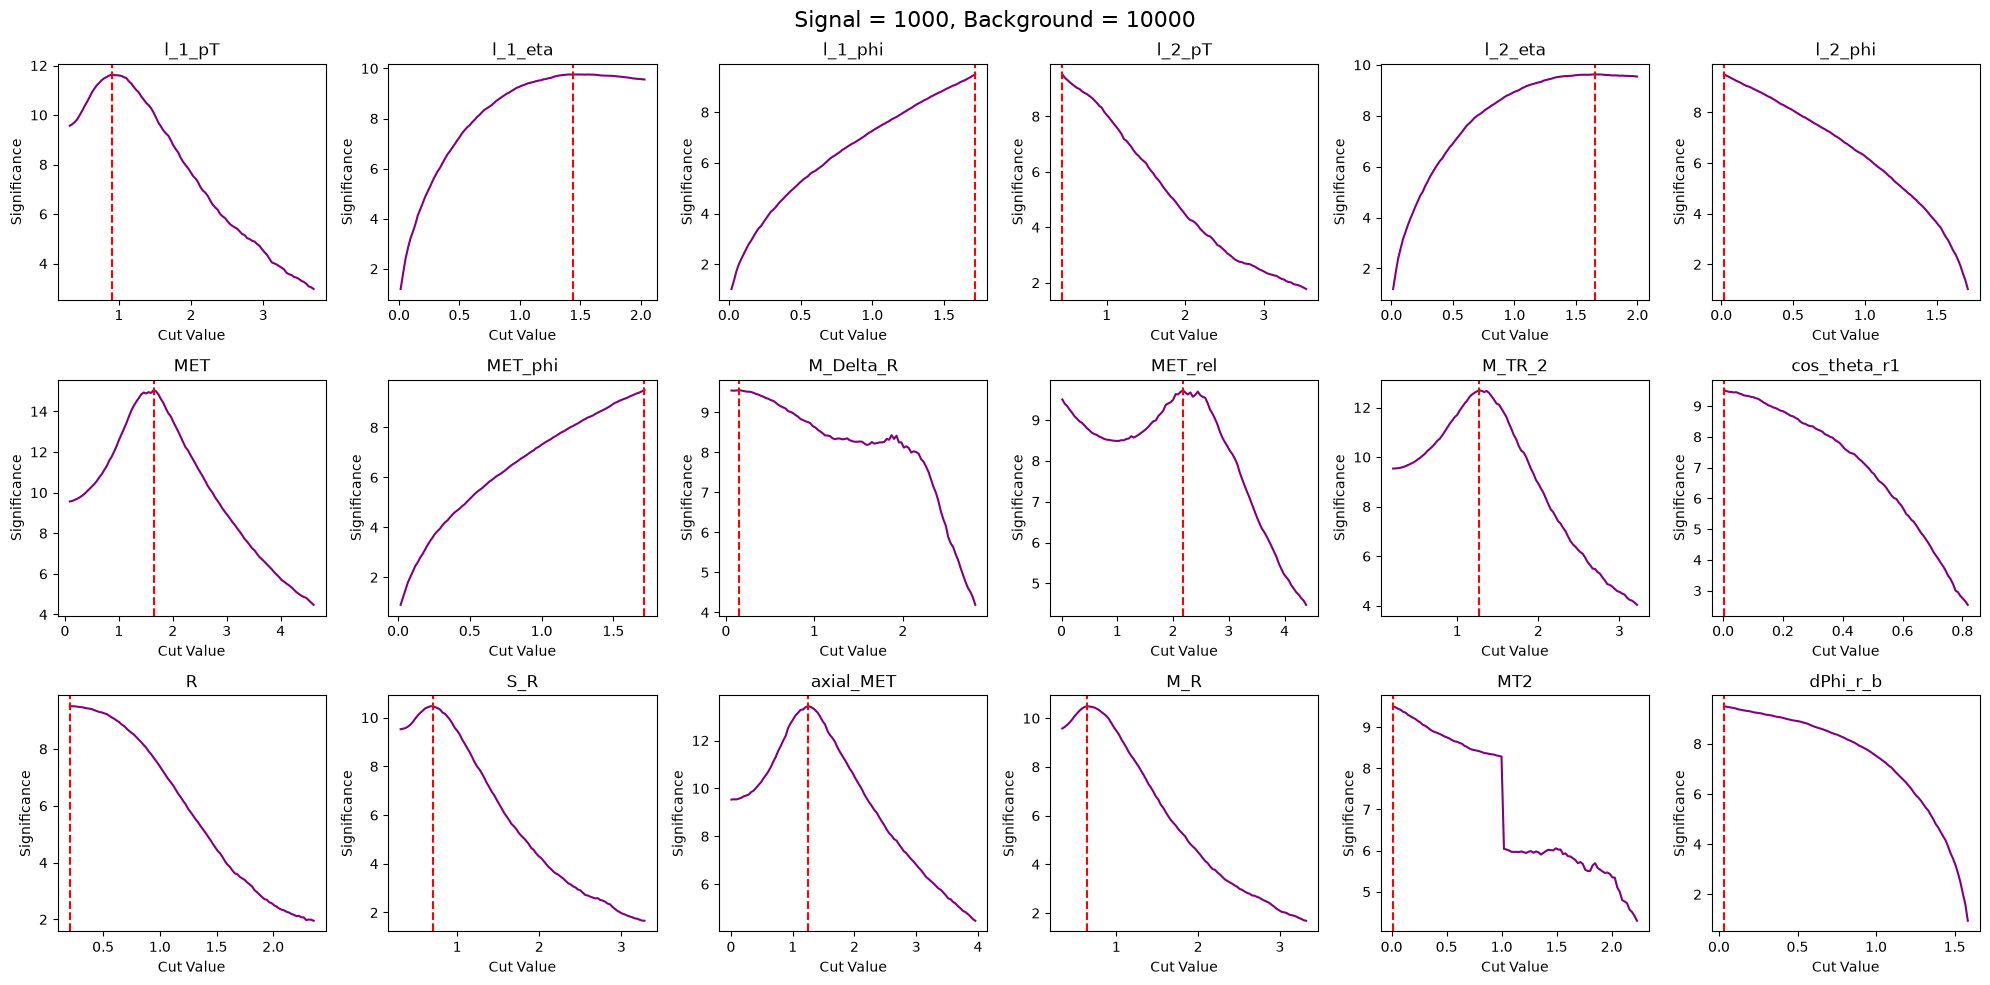

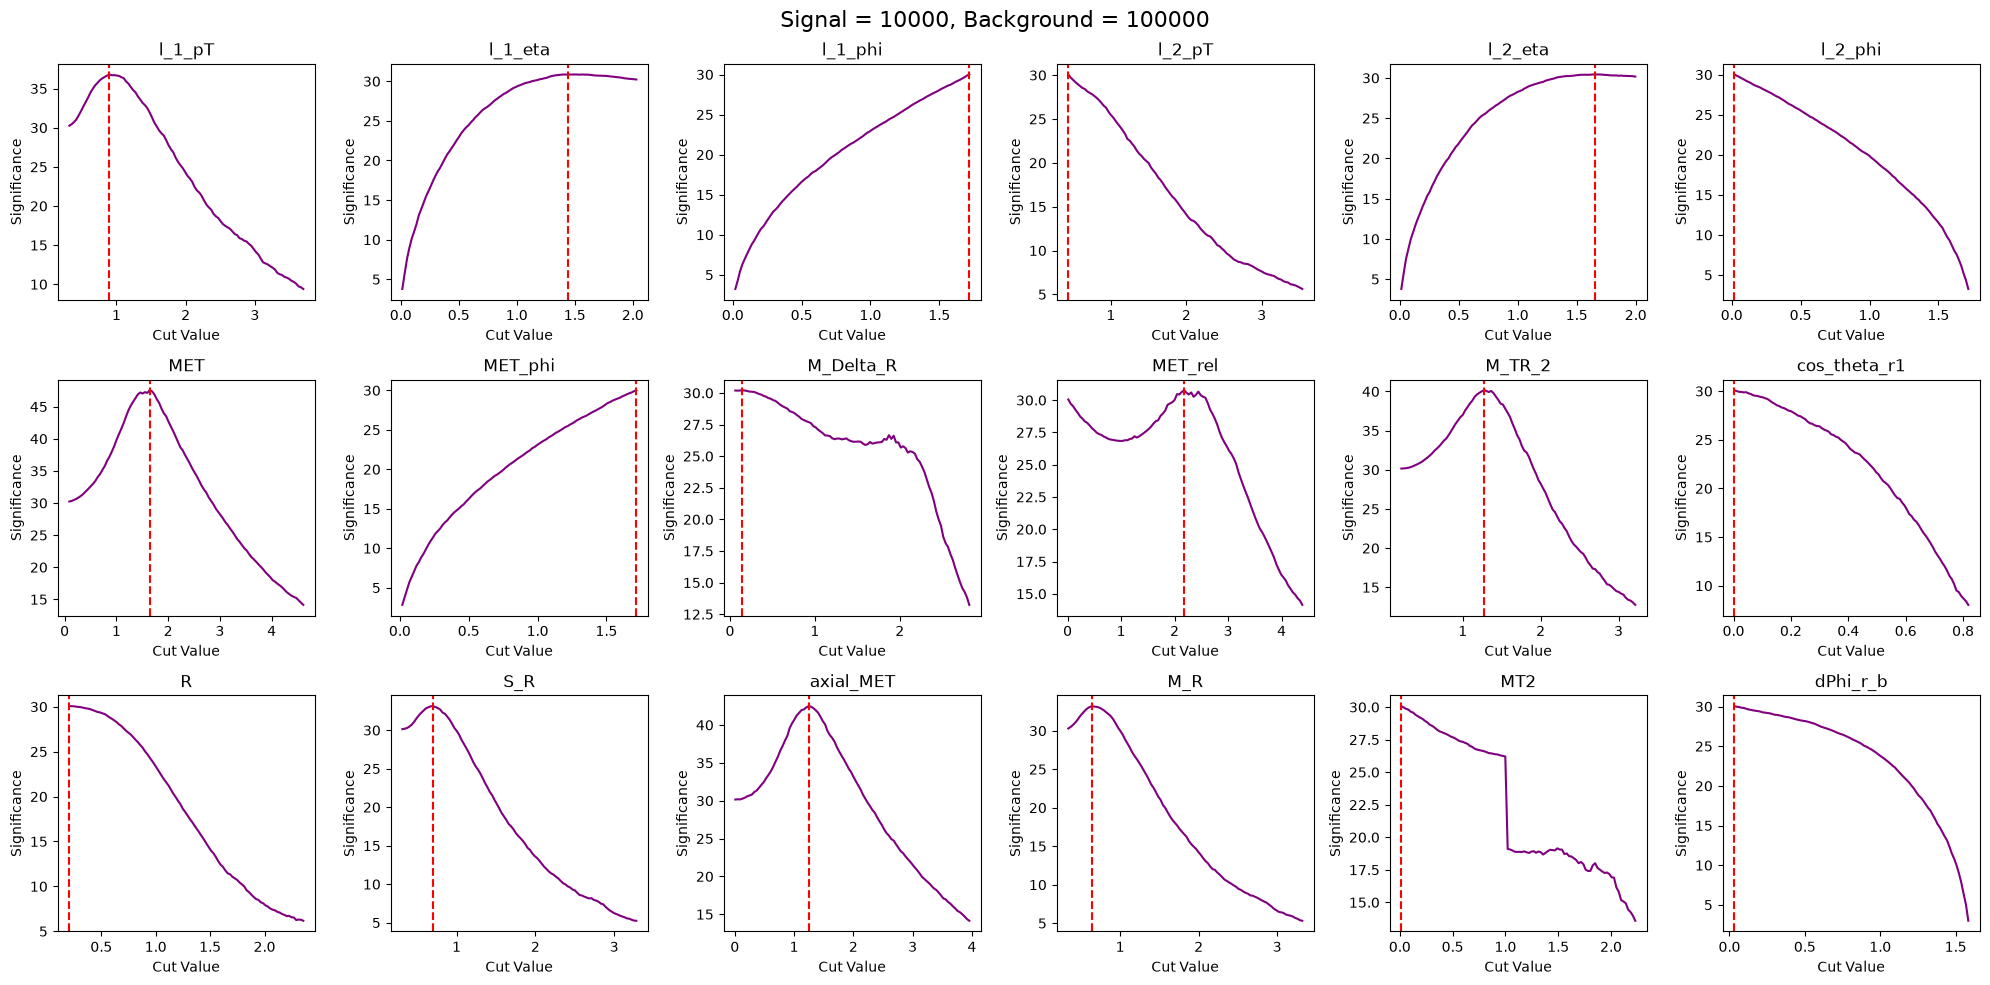

In [35]:

# Exercise 5.3 - Significance

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

best_cuts = {}

for ns, nb in scenarios:

    fig, axes = plt.subplots(3, 6, figsize=(20, 10))
    best_cuts[(ns, nb)] = {}

    for i, var in enumerate(variables):

        ax = axes.flat[i]

        cuts = cut_values[var]
        tpr, fpr = efficiencies[var]

        # Events remaining after selection
        ns_new = tpr * ns
        nb_new = fpr * nb

        # Calculate significance
        total = ns_new + nb_new

        significance = np.divide(
            ns_new,
            np.sqrt(total),
            out=np.zeros_like(ns_new),
            where=total > 0
        )

        ax.plot(cuts, significance, color="purple")

        # Find the best cutoff
        best_index = np.argmax(significance)
        best_cut = cuts[best_index]

        best_cuts[(ns, nb)][var] = (
            best_cut,
            significance[best_index]
        )

        ax.axvline(best_cut, color="red", linestyle="--")

        ax.set_title(var)
        ax.set_xlabel("Cut Value")
        ax.set_ylabel("Significance")

    fig.suptitle(f"Signal = {ns}, Background = {nb}", fontsize=16)
    plt.tight_layout()
    plt.show()


## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [36]:

# Exercise 6.1

selected_cuts = {}

for ns, nb in scenarios:

    # Ranking variables by their highest significance from Exercise 5.3
    ranked = sorted(
        best_cuts[(ns, nb)],
        key=lambda var: best_cuts[(ns, nb)][var][1],
        reverse=True
    )

    top_three = ranked[:3]
    selected_cuts[(ns, nb)] = []

    # Save each variable's selection rule and cutoff
    for var in top_three:
        cutoff = best_cuts[(ns, nb)][var][0]
        selected_cuts[(ns, nb)].append((var, rules[var], cutoff))

    print("\nScenario:", ns, "signal,", nb, "background")

    for var, rule, cutoff in selected_cuts[(ns, nb)]:
        print(var, rule_names[rule], "cutoff =", round(cutoff, 3))



Scenario: 10 signal, 100 background
MET x > xc cutoff = 1.643
axial_MET |x - mu| > xc cutoff = 1.245
M_TR_2 x > xc cutoff = 1.273

Scenario: 100 signal, 1000 background
MET x > xc cutoff = 1.643
axial_MET |x - mu| > xc cutoff = 1.245
M_TR_2 x > xc cutoff = 1.273

Scenario: 1000 signal, 10000 background
MET x > xc cutoff = 1.643
axial_MET |x - mu| > xc cutoff = 1.245
M_TR_2 x > xc cutoff = 1.273

Scenario: 10000 signal, 100000 background
MET x > xc cutoff = 1.643
axial_MET |x - mu| > xc cutoff = 1.245
M_TR_2 x > xc cutoff = 1.273


In [37]:

# Exercise 6.2

import tabulate
from IPython.display import HTML, display

# Return True for events that pass the chosen selection rule
def passes_cut(data, var, rule, cutoff, mu):

    if rule == 1:
        return data[var] > cutoff
    if rule == 2:
        return data[var] < cutoff
    if rule == 3:
        return np.abs(data[var] - mu) > cutoff

    return np.abs(data[var] - mu) < cutoff


for ns, nb in scenarios:

    s_remaining = sig.copy()
    b_remaining = bkg.copy()

    # Start with 100% signal and background efficiency
    rows = [
        ["Before cuts", 1, 1, ns, nb, ns / np.sqrt(ns + nb)]
    ]

    for var, rule, cutoff in selected_cuts[(ns, nb)]:

        mu = np.mean(np.concatenate([sig[var], bkg[var]]))

        # Apply each cut to the events that survived previous cuts
        s_remaining = s_remaining[
            passes_cut(s_remaining, var, rule, cutoff, mu)
        ]

        b_remaining = b_remaining[
            passes_cut(b_remaining, var, rule, cutoff, mu)
        ]

        # Compare surviving events against the original sample
        es = len(s_remaining) / len(sig)
        eb = len(b_remaining) / len(bkg)

        ns_new = es * ns
        nb_new = eb * nb

        # Calculate significance after each successive selection
        total = ns_new + nb_new
        significance = ns_new / np.sqrt(total) if total > 0 else 0

        rows.append([
            var, round(es, 3), round(eb, 3),
            round(ns_new, 2), round(nb_new, 2),
            round(significance, 3)
        ])

    print("\nScenario:", ns, "signal,", nb, "background")

    display(HTML(tabulate.tabulate(
        rows,
        headers=["Cut", "eS", "eB", "NS'", "NB'", "Significance"],
        tablefmt="html"
    )))



Scenario: 10 signal, 100 background


Cut,eS,eB,NS',NB',Significance
Before cuts,1,1,10,100,0.953463
MET,0.295,0.009,2.95,0.91,1.504
axial_MET,0.217,0.006,2.17,0.64,1.293
M_TR_2,0.159,0.006,1.59,0.56,1.085



Scenario: 100 signal, 1000 background


Cut,eS,eB,NS',NB',Significance
Before cuts,1,1,100,1000,3.01511
MET,0.295,0.009,29.54,9.05,4.755
axial_MET,0.217,0.006,21.66,6.4,4.089
M_TR_2,0.159,0.006,15.88,5.55,3.43



Scenario: 1000 signal, 10000 background


Cut,eS,eB,NS',NB',Significance
Before cuts,1,1,1000,10000,9.53463
MET,0.295,0.009,295.4,90.5,15.037
axial_MET,0.217,0.006,216.6,64,12.93
M_TR_2,0.159,0.006,158.75,55.5,10.846



Scenario: 10000 signal, 100000 background


Cut,eS,eB,NS',NB',Significance
Before cuts,1,1,10000,100000,30.1511
MET,0.295,0.009,2954,905,47.552
axial_MET,0.217,0.006,2166,640,40.89
M_TR_2,0.159,0.006,1587.5,555,34.297


In [38]:
# Exercise 6.3

# Compare two related observables
var1 = "MET"
var2 = "MET_rel"

ns, nb = scenarios[0]

def optimize_second(first, second):

    first_rule = rules[first]
    first_cut = best_cuts[(ns, nb)][first][0]

    mu1 = np.mean(np.concatenate([sig[first], bkg[first]]))

    # Apply the first variable's original optimal cutoff
    s1 = sig[passes_cut(sig, first, first_rule, first_cut, mu1)]
    b1 = bkg[passes_cut(bkg, first, first_rule, first_cut, mu1)]

    second_rule = rules[second]
    mu2 = np.mean(np.concatenate([sig[second], bkg[second]]))

    values = np.concatenate([sig[second], bkg[second]])

    if second_rule >= 3:
        values = np.abs(values - mu2)

    cuts = np.linspace(
        np.percentile(values, 1),
        np.percentile(values, 99),
        100
    )

    best_sig = -1
    best_cut = None

    # Re-optimize the second cutoff after applying the first
    for cutoff in cuts:

        s2 = s1[passes_cut(s1, second, second_rule, cutoff, mu2)]
        b2 = b1[passes_cut(b1, second, second_rule, cutoff, mu2)]

        es = len(s2) / len(sig)
        eb = len(b2) / len(bkg)

        ns_new = es * ns
        nb_new = eb * nb

        total = ns_new + nb_new
        significance = ns_new / np.sqrt(total) if total > 0 else 0

        if significance > best_sig:
            best_sig = significance
            best_cut = cutoff

    return best_cut, best_sig


# Reverse the selection order to compare the results
cut1, score1 = optimize_second(var1, var2)
cut2, score2 = optimize_second(var2, var1)

print(var1, "then", var2, ":", round(score1, 3))
print(var2, "then", var1, ":", round(score2, 3))

print("Best second cutoff, first order:", round(cut1, 3))
print("Best second cutoff, reverse order:", round(cut2, 3))


MET then MET_rel : 1.501
MET_rel then MET : 1.063
Best second cutoff, first order: 0.014
Best second cutoff, reverse order: 1.734


For the most of excercise 6 i had used chat since the method and think was not clicking alr for me and work it out in that sense and i also had it clear up most of my errors since i was making a lot from indention etc. then i had chat explain it and learn from it

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



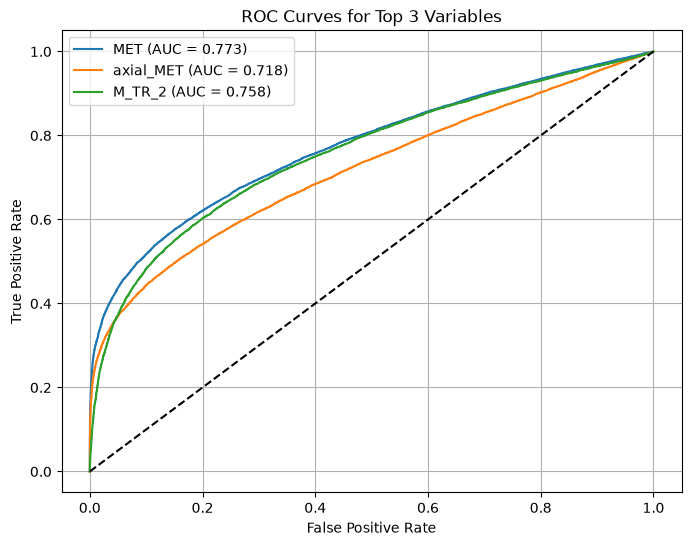

In [42]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

ns, nb = scenarios[0]
top_three = [var for var, rule, cutoff in selected_cuts[(ns, nb)]]

plt.figure(figsize=(8,6))

for var in top_three:
    scores = np.concatenate([sig[var], bkg[var]])
    labels = np.concatenate([np.ones(len(sig)), np.zeros(len(bkg))])

    #Reverse the scores if th smaller values indicate signal

    if rules[var] == 2:
        scores = - scores
    elif rules[var] == 3:
        mu = np.mean(scores)
        scores = np.abs(scores - mu)
    elif rules[var] == 4:
        mu = np.mean(scores)
        scores = -np.abs(scores - mu)

    fpr, tpr, thresholds = roc_curve(labels, scores)
    area = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{var} (AUC = {area:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Top 3 Variables")
plt.legend()
plt.grid(True)
plt.show()


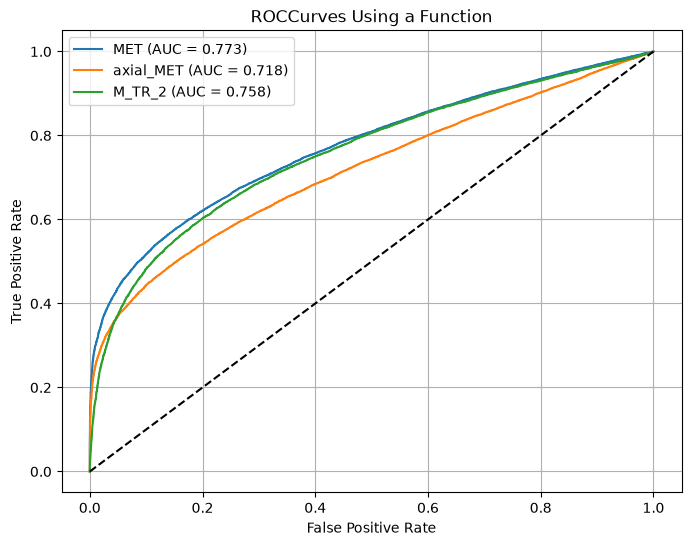

In [43]:
def plot_roc(data_sig, data_bkg, var):

    scores = np.concatenate([data_sig[var], data_bkg[var]])
    labels = np.concatenate([
        np.ones(len(data_sig)),
        np.zeros(len(data_bkg))

    ])

    #adjust th scores based on which values indicate signal

    if rules[var] == 2:
        scores = - scores
    elif rules[var] == 3:
        scores = np.abs(scores - np.mean(scores))
    elif rules[var] == 4:
        scores = -np.abs(scores- np.mean(scores))

    fpr, tpr, thresholds = roc_curve(labels, scores)
    area = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{var} (AUC = {area:.3f})")

    return area

plt.figure(figsize=(8, 6))

for var in top_three:
    plot_roc(sig, bkg, var)


plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROCCurves Using a Function")
plt.legend()
plt.grid(True)
plt.show()


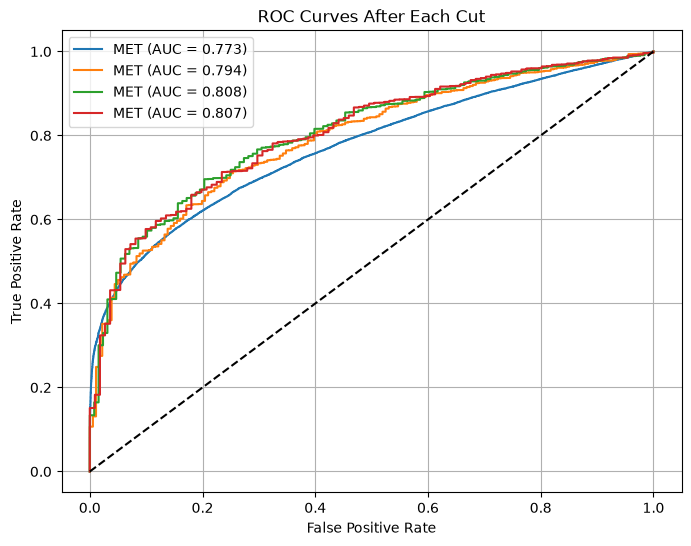

In [44]:

# Exercise 7.3

ns, nb = scenarios[0]

s_remaining = sig.copy()
b_remaining = bkg.copy()

plt.figure(figsize=(8, 6))

# Compare ROC curves before and after each selection
var = top_three[0]
plot_roc(s_remaining, b_remaining, var)

for i, (cut_var, rule, cutoff) in enumerate(selected_cuts[(ns, nb)]):

    mu = np.mean(np.concatenate([sig[cut_var], bkg[cut_var]]))

    # Keep only events that pass the current cut
    s_remaining = s_remaining[
        passes_cut(s_remaining, cut_var, rule, cutoff, mu)
    ]

    b_remaining = b_remaining[
        passes_cut(b_remaining, cut_var, rule, cutoff, mu)
    ]

    if len(s_remaining) == 0 or len(b_remaining) == 0:
        break

    plot_roc(s_remaining, b_remaining, var)

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves After Each Cut")
plt.legend()
plt.grid(True)
plt.show()


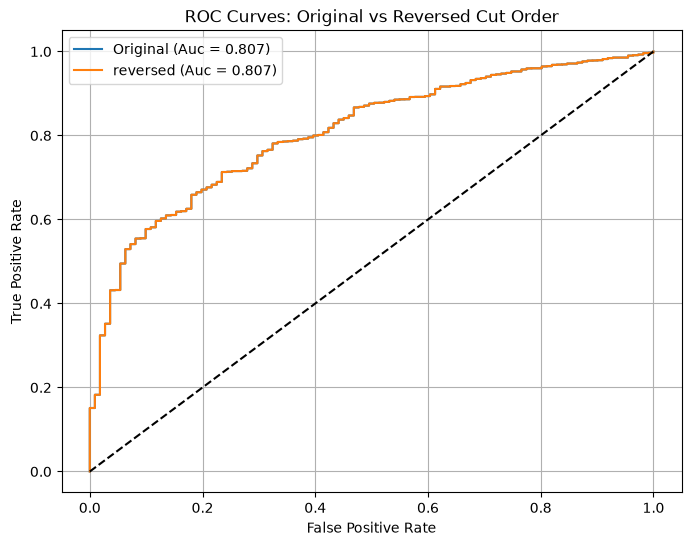

In [46]:
#excercise 7.4

ns, nb = scenarios[0]

cuts = selected_cuts[(ns, nb)]

plt.figure(figsize=(8, 6))

# Compere the orig order with the reversed order
for order, name in [(cuts, "Original"), (cuts[::-1], "reversed")]:

    s_remaining = sig.copy()
    b_remaining = bkg.copy()

    for cut_var, rule, cutoff in order:

        mu = np.mean(np.concatenate([sig[cut_var], bkg[cut_var]]))

        s_remaining = s_remaining[
            passes_cut(s_remaining, cut_var, rule, cutoff, mu)
        ]

        b_remaining = b_remaining[
            passes_cut(b_remaining, cut_var, rule, cutoff, mu)
        ]

    if len(s_remaining) == 0 or len(b_remaining) == 0:
        continue

    scores = np.concatenate([s_remaining[var], b_remaining[var]])
    labels = np.concatenate([
        np.ones(len(s_remaining)),
        np.zeros(len(b_remaining))
    ])

    if rules[var] == 2:
        scores = -scores
    elif rules[var] ==3:
        scores = np.abs(scores - np.mean(scores))
    elif rules[var] == 4:
        scores = -np.abs(scores - np.mean(scores))

    fpr, tpr, thresholds = roc_curve(labels, scores)
    area = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (Auc = {area:.3f})")


plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Original vs Reversed Cut Order")
plt.legend()
plt.grid(True)
plt.show()


For this one i had chat clearn up 5 mistakes  and fix up logic errors that were gicing me errors

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [47]:
#8.1
X_sig = sig[variables].to_numpy()
X_bkg = bkg[variables].to_numpy()

#locate the avg of each variable for both of the groups

m1 = np.mean(X_sig, axis=0)
m2 = np.mean(X_bkg, axis=0)

#meauser the difference betweent the 2 groups
difference = m2 - m1
SB = np.outer(difference, difference)

#measure how much each group will vary for the mean

sig_centered = X_sig - m1
bkg_centered = X_bkg - m2

SW = sig_centered.T @ sig_centered + bkg_centered.T @ bkg_centered

print("Betwen the class matrix:")
print(SB)

print("\nWithin-class matrix:")
print(SW)

print("\nMatrix shapes:", SB.shape, SW.shape)

Betwen the class matrix:
[[ 2.86580145e-01 -3.55386442e-03 -1.04153571e-03  1.31344162e-01
  -6.77970393e-04  5.51922690e-03  4.16789383e-01 -5.58134559e-04
   1.89510444e-01  2.75912309e-01  2.68828010e-01  5.71216937e-02
   5.74541144e-02  1.73766415e-01  7.78181646e-02  1.81321057e-01
   7.61562651e-02  1.76620746e-02]
 [-3.55386442e-03  4.40712749e-05  1.29160263e-05 -1.62879164e-03
   8.40747311e-06 -6.84436256e-05 -5.16858194e-03  6.92139560e-06
  -2.35010847e-03 -3.42157319e-03 -3.33372119e-03 -7.08362945e-04
  -7.12485275e-04 -2.15486764e-03 -9.65018728e-04 -2.24855234e-03
  -9.44409605e-04 -2.19026404e-04]
 [-1.04153571e-03  1.29160263e-05  3.78531677e-06 -4.77352102e-04
   2.46398917e-06 -2.00588631e-05 -1.51476309e-03  2.02846248e-06
  -6.88749372e-04 -1.00276494e-03 -9.77018039e-04 -2.07600857e-04
  -2.08808994e-04 -6.31529884e-04 -2.82819304e-04 -6.58986183e-04
  -2.76779361e-04 -6.41903555e-05]
 [ 1.31344162e-01 -1.62879164e-03 -4.77352102e-04  6.01970833e-02
  -3.1072443

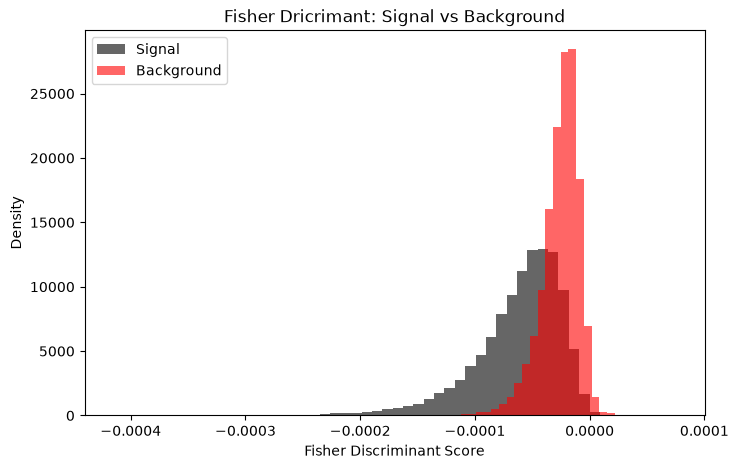

In [49]:


#8.2

# Calculate the coefficients using  within-class matrix
w = np.linalg.solve(SW, m2 -m1)

# Use the coefficients to calculate a score for each event
F_sig = X_sig @ w
F_bkg = X_bkg @ w

plt.figure(figsize=(8, 5))

plt.hist(F_sig, bins=50, density=True,
         alpha= 0.6, color="black", label="Signal")

plt.hist(F_bkg, bins=50, density=True,
         alpha=0.6, color="red", label="Background")

plt.xlabel("Fisher Discriminant Score")
plt.ylabel("Density")
plt.title("Fisher Dricrimant: Signal vs Background")
plt.legend()
plt.show()

For this one in 8,2 i had to use chat since i had my graphs overlaping which needed to be fixed

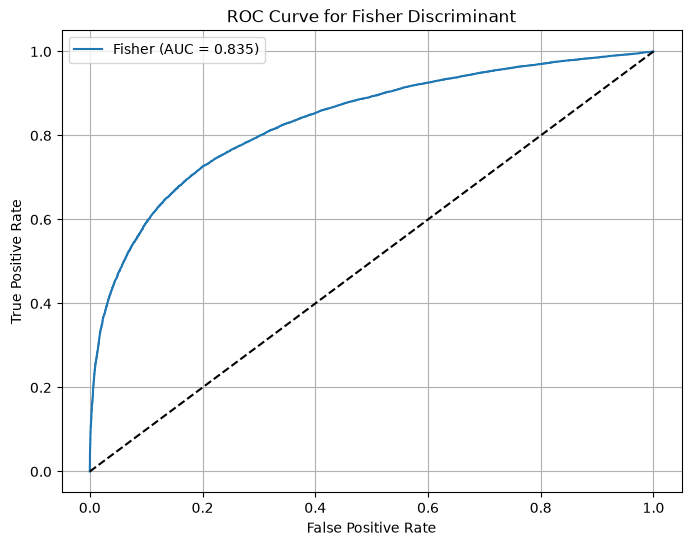

In [ ]:
#8.3



scores  = np.concatenate([F_sig, F_bkg])
labels = np.concatenate([
    np.ones(len(F_sig)),
    np.zeros(len(F_bkg))
])

#reverse the cores since we had alr used bkg minus sig for 8,2

scores = -scores

fpr,tpr, thresholds =roc_curve(labels, scores)
area =auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label =f"Fisher (AUC = {area:.3f})")
plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Fisher Discriminant")
plt.legend()
plt.grid(True)
plt.show()


In [56]:
#8.4

cuts = np.linspace(scores.min(), scores.max(), 200)

results = []

for ns, nb in scenarios:

    best_sig = 0 
    best_cut = 0

    for cutoff in cuts:

        #make count of the fraction of events taht are passing each cuttoff
        es = np.mean(-F_sig > cutoff)
        eb = np.mean(-F_bkg > cutoff)

        ns_new = ns * es
        nb_new = nb *eb

        #calc significance after the selection process
        total = ns_new + nb_new
        significance = ns_new / np.sqrt(total) if total > 0 else 0


        if significance > best_sig:
            best_sig = significance
            best_cut = cutoff

        
    results.append([ns, nb, round(best_cut, 5), round(best_sig, 3)])

    #show the best results for each scenario

import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=["Signal", "Background", "Best Cut", "Max Significance"]
    )

display(results_df)

,Signal,Background,Best Cut,Max Significance
0,10,100,0.00006,1.507
1,100,1000,0.00006,4.766
2,1000,10000,0.00006,15.071
3,10000,100000,0.00006,47.659
